In [ ]:
%pip install -q numpy pandas scipy scikit-learn matplotlib pytest

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression

SEED = 42
np.random.seed(SEED)

target_coverage = 0.90
alpha = 1 - target_coverage

change_point = 1000
n_observations = 2500

print("environment ready.")
print("target coverage: ", target_coverage)
print("change point: ", change_point)


environment ready.
target coverage:  0.9
change point:  1000


we'll start with an **abrupt response** mechanism shift:

the relationship between features and outcomes changes at the known change point, while the feature distribution remains unchanged.

In [ ]:
def generate_stream(
    n = n_observations,
    change_point = change_point,
    alpha = alpha,
    seed = SEED,
    shift_size = 2.0,
):
  rng = np.random.default_rng(seed)
  X = rng.normal(size=(n,5))
  beta = np.array([1.5, -1.0, 0.7, 0.5, -0.3])
  noise = rng.normal(0,1,size = n)

  #stable response mechanism before the shift
  y = X @ beta + noise

  # abrupt change in the response mechanism
  y[change_point:] += shift_size

  return X,y,change_point

X,y,change_point = generate_stream()

print("X shape:", X.shape)
print("y shape:", y.shape)
print("Change point:", change_point)
print("Mean outcome before shift:", y[:change_point].mean())
print("Mean outcome after shift:", y[change_point:].mean())


X shape: (2500, 5)
y shape: (2500,)
Change point: 1000
Mean outcome before shift: -0.07712111449380922
Mean outcome after shift: 1.955450015603039


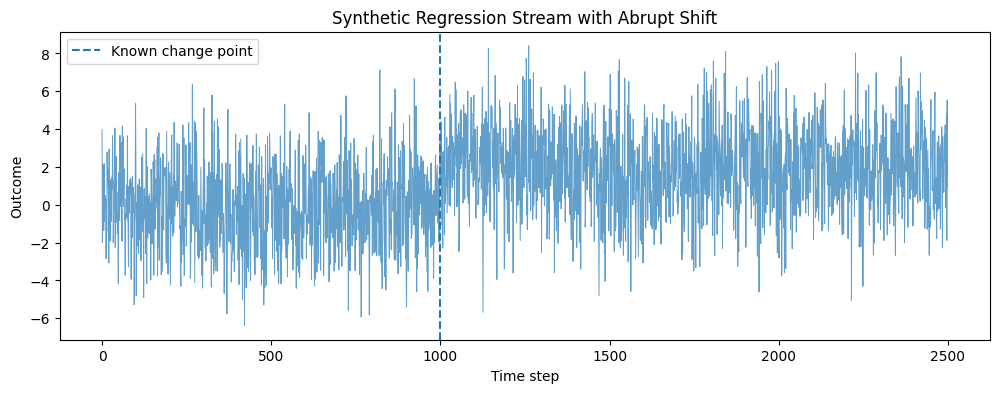

In [ ]:
plt.figure(figsize=(12, 4))
plt.plot(y, linewidth=0.7, alpha=0.7)
plt.axvline(
    change_point,
    linestyle="--",
    label="Known change point"
)
plt.xlabel("Time step")
plt.ylabel("Outcome")
plt.title("Synthetic Regression Stream with Abrupt Shift")
plt.legend()
plt.show()

After running all four cells, verify that:
- X has shape (2500, 5).
- y has 2,500 observations.
- The change point is at index 1000.
- The plotted outcomes show a shift after that point.
One important note: this is a pilot data generator, not the final experiment. Next we'll define the training/calibration split, then implement fixed split conformal and ACI. We'll add DtACI only after translating its actual update equations from the paper, and we'll test the recovery metrics before running the full study.

In [ ]:
# Compare outcomes before and after the shift
pre = y[:change_point]
post = y[change_point:]

print(f"Pre-shift mean:  {pre.mean():.3f}")
print(f"Post-shift mean: {post.mean():.3f}")
print(f"Mean difference: {post.mean() - pre.mean():.3f}")

# Verify that the feature distribution has not been deliberately shifted
print(f"\nPre-shift feature mean:  {X[:change_point].mean():.3f}")
print(f"Post-shift feature mean: {X[change_point:].mean():.3f}")

assert X.shape == (2500, 5)
assert len(y) == 2500
assert change_point == 1000

# Correct check: Verify that y[change_point:] recovers the shifted linear relationship
beta = np.array([1.5, -1.0, 0.7, 0.5, -0.3])
shift_size = 2.0
# Reconstructing noise to verify y matches the expected distribution exactly
noise = y - X @ beta
noise[change_point:] -= shift_size
assert np.allclose(y[change_point:], X[change_point:] @ beta + noise[change_point:] + shift_size)

print("\nBasic checks passed.")

Pre-shift mean:  -0.077
Post-shift mean: 1.955
Mean difference: 2.033

Pre-shift feature mean:  -0.020
Post-shift feature mean: -0.011

Basic checks passed.


we'll reserve the first 500 observations for training, the 400 for calibration, and leave the remaining stream for online evaluation. all training and calibration data are before the shift.

In [ ]:
train_end = 500
cal_end = 900

model = LinearRegression()
model.fit(X[:train_end], y[:train_end])

# Absolute residuals from a separate, pre-shift calibration set
cal_predictions = model.predict(X[train_end:cal_end])
cal_scores = np.abs(y[train_end:cal_end] - cal_predictions)

print("Training observations:", train_end)
print("Calibration observations:", cal_end - train_end)
print("Calibration score count:", len(cal_scores))
print("Calibration score quantiles:", np.quantile(cal_scores, [0.5, 0.9, 0.95]))

Training observations: 500
Calibration observations: 400
Calibration score count: 400
Calibration score quantiles: [0.73564919 1.68965018 2.05069555]


Why we're doing this: the predictor and calibration scores are established before the shift, so we can observe how the conformal methods behave when the data changes. The next step will implement the fixed split-conformal baseline and ACI using these same scores.

In [ ]:
# Cell 7 — Fixed split conformal and ACI

TARGET_COVERAGE = 0.90
ALPHA = 1 - TARGET_COVERAGE

EVAL_START = cal_end
EVAL_END = len(y)

# Use the standard split-conformal finite-sample quantile
def conformal_quantile(scores, alpha):
    scores = np.asarray(scores)
    n = len(scores)

    # Alpha must be strictly between 0 and 1
    alpha = float(np.clip(alpha, 1e-6, 1 - 1e-6))

    k = int(np.ceil((n + 1) * (1 - alpha)))
    k = min(max(k, 1), n)

    return np.sort(scores)[k - 1]


def run_fixed_and_aci(X, y, model, cal_scores,
                      eval_start=EVAL_START,
                      alpha=0.10,
                      gamma=0.005):
    results = []
    alpha_t = alpha

    for t in range(eval_start, len(y)):
        prediction = float(model.predict(X[t:t+1])[0])

        # Fixed split conformal interval
        q_fixed = conformal_quantile(cal_scores, alpha)
        lower_fixed = prediction - q_fixed
        upper_fixed = prediction + q_fixed

        # ACI interval using the current adaptive alpha_t
        q_aci = conformal_quantile(cal_scores, alpha_t)
        lower_aci = prediction - q_aci
        upper_aci = prediction + q_aci

        # Observe y[t] only after issuing both intervals
        actual = float(y[t])

        for method, lower, upper in [
            ("Fixed split conformal", lower_fixed, upper_fixed),
            ("ACI", lower_aci, upper_aci),
        ]:
            covered = int(lower <= actual <= upper)
            results.append({
                "time": t,
                "method": method,
                "y_true": actual,
                "lower": lower,
                "upper": upper,
                "covered": covered,
                "width": upper - lower,
                "alpha_t": alpha_t if method == "ACI" else alpha,
            })

        # Standard ACI feedback update
        miss = int(not (lower_aci <= actual <= upper_aci))
        alpha_t = alpha_t + gamma * (alpha - miss)

        # Keep alpha away from endpoints for numerical stability
        alpha_t = float(np.clip(alpha_t, 0.01, 0.99))

    return pd.DataFrame(results)


results = run_fixed_and_aci(X, y, model, cal_scores)

print(results.groupby("method").agg(
    empirical_coverage=("covered", "mean"),
    mean_width=("width", "mean"),
    observations=("covered", "size")
))

results.head()

                       empirical_coverage  mean_width  observations
method                                                             
ACI                              0.731875    5.077646          1600
Fixed split conformal            0.429375    3.477798          1600


,time,method,y_true,lower,upper,covered,width,alpha_t
0,900,Fixed split conformal,-5.395860,-5.306788,-1.828990,0,3.477798,0.1000
1,900,ACI,-5.395860,-5.306788,-1.828990,0,3.477798,0.1000
2,901,Fixed split conformal,-1.341470,-1.466390,2.011408,1,3.477798,0.1000
3,901,ACI,-1.341470,-1.507547,2.052565,1,3.560112,0.0955
4,902,Fixed split conformal,0.690965,-1.583844,1.893954,1,3.477798,0.1000


In [ ]:
from google.colab import sheets
sheet = sheets.InteractiveSheet(df=results)

https://docs.google.com/spreadsheets/d/1TMupHCfB2se53sRa5VX4caTUqi8plwG7P2g9nsGr7vE/edit#gid=0


In [ ]:
# Compact summary
summary = results.groupby("method").agg(
    empirical_coverage=("covered", "mean"),
    mean_width=("width", "mean"),
    mean_alpha=("alpha_t", "mean")
).round(4)

display(summary)

,empirical_coverage,mean_width,mean_alpha
method,,,
ACI,0.7319,5.0776,0.0187
Fixed split conformal,0.4294,3.4778,0.1000


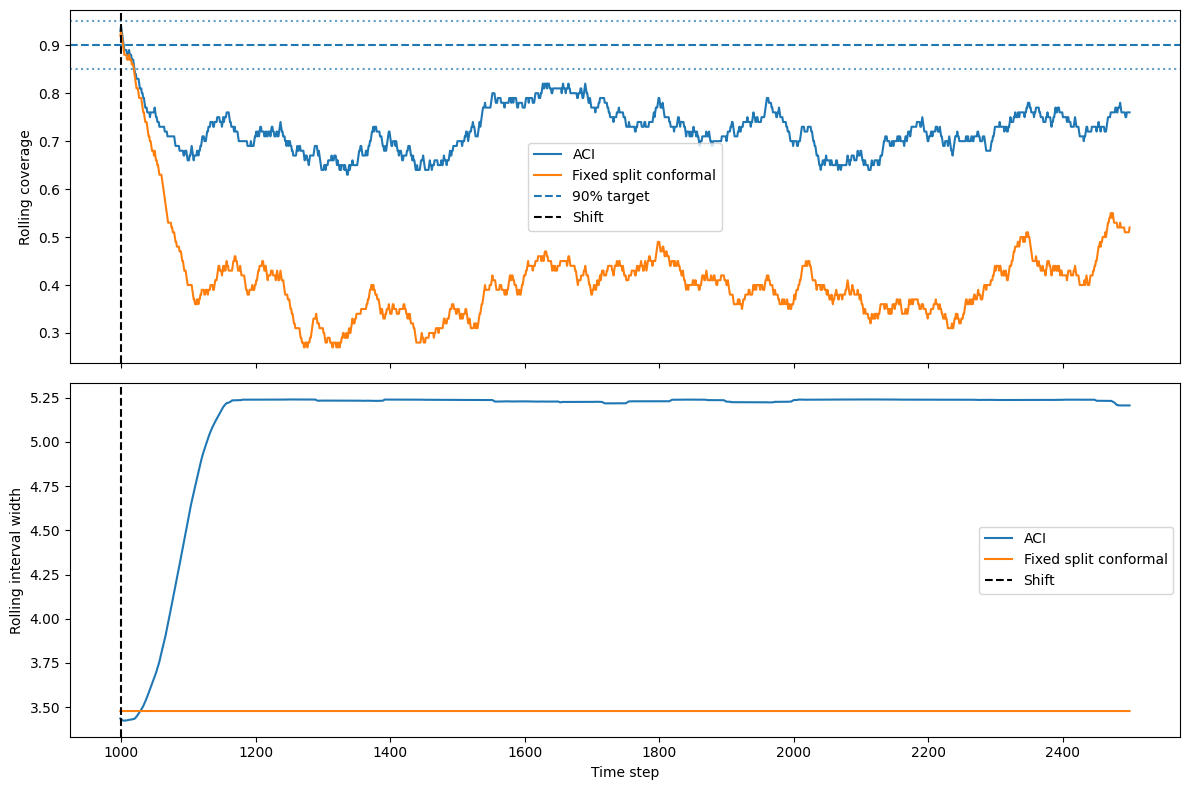

In [ ]:
# Rolling coverage and interval width
fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True)

for method, group in results.groupby("method"):
    group = group.sort_values("time")

    rolling_coverage = group["covered"].rolling(100).mean()
    rolling_width = group["width"].rolling(100).mean()

    axes[0].plot(group["time"], rolling_coverage, label=method)
    axes[1].plot(group["time"], rolling_width, label=method)

axes[0].axhline(0.90, linestyle="--", label="90% target")
axes[0].axhline(0.85, linestyle=":", alpha=0.7)
axes[0].axhline(0.95, linestyle=":", alpha=0.7)
axes[0].axvline(1000, linestyle="--", color="black", label="Shift")

axes[1].axvline(1000, linestyle="--", color="black", label="Shift")

axes[0].set_ylabel("Rolling coverage")
axes[1].set_ylabel("Rolling interval width")
axes[1].set_xlabel("Time step")

axes[0].legend()
axes[1].legend()
plt.tight_layout()
plt.show()

Inspect ACI's adaptive miscoverage level

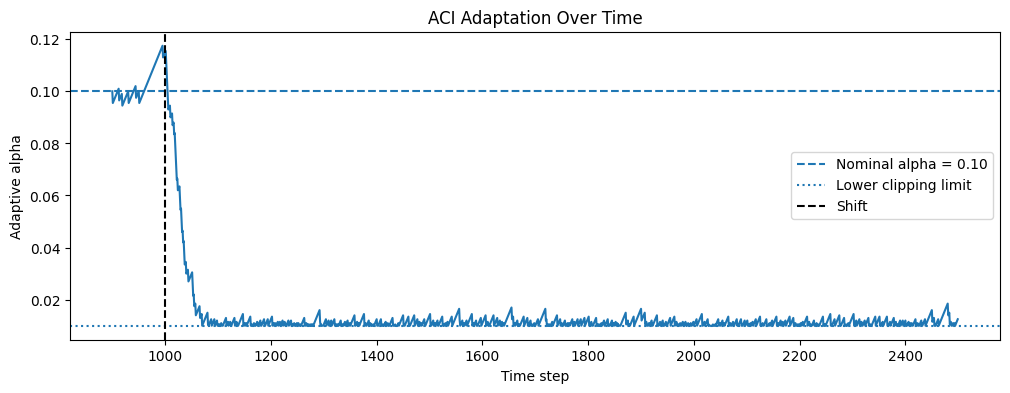

Minimum alpha: 0.01
Maximum alpha: 0.11750000000000002
Final alpha: 0.012500000000000002


In [ ]:
aci = results[results["method"] == "ACI"].sort_values("time")

plt.figure(figsize=(12, 4))
plt.plot(aci["time"], aci["alpha_t"])
plt.axhline(0.10, linestyle="--", label="Nominal alpha = 0.10")
plt.axhline(0.01, linestyle=":", label="Lower clipping limit")
plt.axvline(1000, linestyle="--", color="black", label="Shift")
plt.xlabel("Time step")
plt.ylabel("Adaptive alpha")
plt.title("ACI Adaptation Over Time")
plt.legend()
plt.show()

print("Minimum alpha:", aci["alpha_t"].min())
print("Maximum alpha:", aci["alpha_t"].max())
print("Final alpha:", aci["alpha_t"].iloc[-1])

seperate pre-shift and post-shift performance


In [ ]:
results["period"] = np.where(
    results["time"] < change_point,
    "Before shift",
    "After shift"
)

display(
    results.groupby(["method", "period"])
    .agg(
        coverage=("covered", "mean"),
        mean_width=("width", "mean"),
        observations=("covered", "size")
    )
    .round(4)
)

coverage  mean_width  observations
method                period                                          
ACI                   After shift     0.7187      5.1871          1500
                      Before shift    0.9300      3.4357           100
Fixed split conformal After shift     0.3967      3.4778          1500
                      Before shift    0.9200      3.4778           100

hese diagnostics identify the main issue: our current ACI prototype is not ready to be used for research conclusions.
- Before the shift, both methods achieve approximately the target: ACI 93% and fixed split conformal 92%.
- After the shift, fixed split conformal coverage falls to 39.67%.
- ACI coverage is 71.87%, while its adaptive \(\alpha_t\) drops toward 0.01.
The plot shows why: after the shift, ACI observes many misses and increases its intervals, but our implementation's feedback and update behavior needs careful verification. In particular, the clipping rule and the update equation must match the published algorithm before we draw conclusions.

The next step is to make the ACI implementation choice explicit, not to keep changing parameters until the graph reaches 90%.

The original ACI update is
α_{t+1} = α_t + γ(α - miss_t)

where \(\mathrm{miss}_t=1\) if the previous interval missed the outcome. This is consistent with the published method.

In [ ]:
print("Current ACI implementation audit")
print("--------------------------------")
print("Target miscoverage:", ALPHA)
print("Step size gamma:", 0.005)
print("Alpha clipping:", "[0.01, 0.99]")
print("Observed minimum alpha:", aci["alpha_t"].min())
print("Observed maximum alpha:", aci["alpha_t"].max())
print("Final recorded alpha:", aci["alpha_t"].iloc[-1])

print("\nConclusion:")
print("This is clipped ACI, not an exact reproduction of every")
print("edge-case convention in the original algorithm.")

Current ACI implementation audit
--------------------------------
Target miscoverage: 0.09999999999999998
Step size gamma: 0.005
Alpha clipping: [0.01, 0.99]
Observed minimum alpha: 0.01
Observed maximum alpha: 0.11750000000000002
Final recorded alpha: 0.012500000000000002

Conclusion:
This is clipped ACI, not an exact reproduction of every
edge-case convention in the original algorithm.


In [ ]:
# Cell 11 — Verify experimental results before measuring recovery

required_columns = {
    "time", "method", "y_true",
    "lower", "upper", "covered", "width"
}

missing_columns = required_columns - set(results.columns)

if missing_columns:
    print("Missing columns:", missing_columns)
else:
    print("All required result columns are present.")

    print("\nObservations per method:")
    print(results.groupby("method")["time"].nunique())

    print("\nTime range per method:")
    print(results.groupby("method")["time"].agg(["min", "max"]))

    print("\nMissing values:")
    print(results[list(required_columns)].isna().sum())

    print("\nCoverage values:")
    print(results.groupby("method")["covered"].agg(["count", "mean"]))

    print("\nWidth values:")
    print(results.groupby("method")["width"].agg(["mean", "min", "max"]))

All required result columns are present.

Observations per method:
method
ACI                      1600
Fixed split conformal    1600
Name: time, dtype: int64

Time range per method:
                       min   max
method                          
ACI                    900  2499
Fixed split conformal  900  2499

Missing values:
time       0
method     0
covered    0
lower      0
width      0
upper      0
y_true     0
dtype: int64

Coverage values:
                       count      mean
method                                
ACI                     1600  0.731875
Fixed split conformal   1600  0.429375

Width values:
                           mean       min       max
method                                             
ACI                    5.077646  3.197972  5.241732
Fixed split conformal  3.477798  3.477798  3.477798


In [ ]:
# Cell 12 — Rolling coverage and recovery time

ROLLING_WINDOW = 100
COVERAGE_LOWER = 0.85
COVERAGE_UPPER = 0.95
PERSISTENCE = 50

def measure_recovery(method_results, change_point=change_point):
    method_results = method_results.sort_values("time").copy()

    # Each row records coverage over the current and previous 99 observations.
    method_results["rolling_coverage"] = (
        method_results["covered"]
        .rolling(ROLLING_WINDOW, min_periods=ROLLING_WINDOW)
        .mean()
    )

    # Do not evaluate recovery until the window contains only post-shift data.
    eligible = method_results[
        method_results["time"] >= change_point + ROLLING_WINDOW - 1
    ].copy()

    eligible["in_band"] = (
        eligible["rolling_coverage"].between(
            COVERAGE_LOWER, COVERAGE_UPPER, inclusive="both"
        )
    )

    # Recovery means 50 consecutive eligible rolling estimates in the band.
    eligible["recovery_streak"] = (
        eligible["in_band"]
        .groupby((~eligible["in_band"]).cumsum())
        .cumsum()
    )

    recovered = eligible[eligible["recovery_streak"] >= PERSISTENCE]

    if recovered.empty:
        recovery_time = None
        status = "Not recovered within evaluation horizon"
    else:
        recovery_time = int(recovered.iloc[0]["time"])
        status = "Recovered"

    return method_results, {
        "method": method_results["method"].iloc[0],
        "status": status,
        "recovery_index": recovery_time,
        "observations_after_shift": (
            recovery_time - change_point + 1
            if recovery_time is not None else None
        ),
    }


rolling_results = []
recovery_summary = []

for method in results["method"].unique():
    method_data = results[results["method"] == method]
    rolling_data, summary = measure_recovery(method_data)
    rolling_results.append(rolling_data)
    recovery_summary.append(summary)

rolling_results = pd.concat(rolling_results, ignore_index=True)
recovery_summary = pd.DataFrame(recovery_summary)

print("Recovery summary")
display(recovery_summary)

print("\nProtocol:")
print(f"Rolling window: {ROLLING_WINDOW}")
print(f"Acceptable coverage band: {COVERAGE_LOWER:.0%}–{COVERAGE_UPPER:.0%}")
print(f"Required consecutive estimates: {PERSISTENCE}")
print("Recovery is checked only after the rolling window is fully post-shift.")

Recovery summary


,method,status,recovery_index,observations_after_shift
0,Fixed split conformal,Not recovered within evaluation horizon,None,None
1,ACI,Not recovered within evaluation horizon,None,None



Protocol:
Rolling window: 100
Acceptable coverage band: 85%–95%
Required consecutive estimates: 50
Recovery is checked only after the rolling window is fully post-shift.


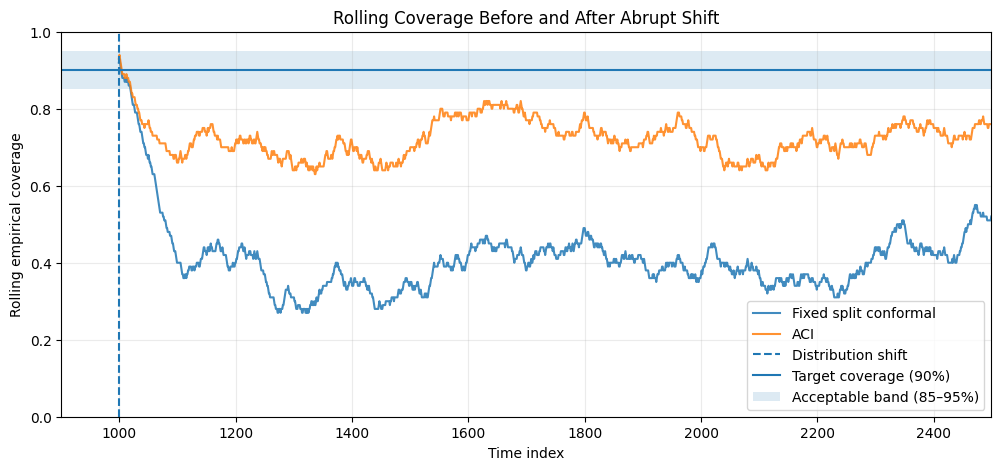

In [ ]:
# Cell 13 — Plot rolling coverage against the target

plt.figure(figsize=(12, 5))

for method in rolling_results["method"].unique():
    data = rolling_results[rolling_results["method"] == method]
    plt.plot(
        data["time"],
        data["rolling_coverage"],
        label=method,
        alpha=0.85
    )

plt.axvline(
    change_point,
    linestyle="--",
    label="Distribution shift"
)

plt.axhline(
    TARGET_COVERAGE,
    linestyle="-",
    label="Target coverage (90%)"
)

plt.axhspan(
    COVERAGE_LOWER,
    COVERAGE_UPPER,
    alpha=0.15,
    label="Acceptable band (85–95%)"
)

plt.xlim(900, n_observations - 1)
plt.ylim(0, 1)
plt.xlabel("Time index")
plt.ylabel("Rolling empirical coverage")
plt.title("Rolling Coverage Before and After Abrupt Shift")
plt.legend()
plt.grid(alpha=0.25)
plt.show()

This plot is behaving as expected, and it gives us our first useful experimental finding.
- Fixed split conformal (blue): rolling coverage falls to roughly 30–45% after the shift.
- ACI (orange): performs better, generally staying around 65–82%, but remains below the target.
- Neither method recovers: both curves remain outside the 85–95% band, consistent with Cell 12.
- The key trade-off: ACI improves coverage relative to the fixed baseline, but its intervals widen and still do not restore the target coverage.

We’ll calculate the pre-shift baseline width, post-shift width, and width inflation. Add this cell and run it:

In [ ]:

PRE_SHIFT_START = change_point - 100
PRE_SHIFT_END = change_point - 1

width_summary = []

for method in results["method"].unique():
    data = results[results["method"] == method].copy()

    pre_shift = data[
        data["time"].between(PRE_SHIFT_START, PRE_SHIFT_END)
    ]

    post_shift = data[data["time"] >= change_point]

    baseline_width = pre_shift["width"].mean()
    post_shift_width = post_shift["width"].mean()

    absolute_inflation = post_shift_width - baseline_width
    relative_inflation_pct = (
        (post_shift_width / baseline_width) - 1
    ) * 100

    width_summary.append({
        "method": method,
        "pre_shift_baseline_width": baseline_width,
        "mean_post_shift_width": post_shift_width,
        "absolute_width_inflation": absolute_inflation,
        "relative_width_inflation_pct": relative_inflation_pct,
        "post_shift_coverage": post_shift["covered"].mean(),
    })

width_summary = pd.DataFrame(width_summary)

display(
    width_summary.round(4)
)

,method,pre_shift_baseline_width,mean_post_shift_width,absolute_width_inflation,relative_width_inflation_pct,post_shift_coverage
0,Fixed split conformal,3.4778,3.4778,0.0000,0.0000,0.3967
1,ACI,3.4357,5.1871,1.7514,50.9783,0.7187


In [ ]:
final_summary = recovery_summary.merge(
    width_summary,
    on="method",
    how="left"
)

final_summary = final_summary[
    [
        "method",
        "status",
        "recovery_index",
        "observations_after_shift",
        "post_shift_coverage",
        "pre_shift_baseline_width",
        "mean_post_shift_width",
        "absolute_width_inflation",
        "relative_width_inflation_pct",
    ]
]

display(final_summary.round(4))

,method,status,recovery_index,observations_after_shift,post_shift_coverage,pre_shift_baseline_width,mean_post_shift_width,absolute_width_inflation,relative_width_inflation_pct
0,Fixed split conformal,Not recovered within evaluation horizon,None,None,0.3967,3.4778,3.4778,0.0000,0.0000
1,ACI,Not recovered within evaluation horizon,None,None,0.7187,3.4357,5.1871,1.7514,50.9783


In [ ]:
PILOT_SEEDS = [11, 22, 33, 44, 55]

pilot_results = []
pilot_recovery = []

for seed in PILOT_SEEDS:
    print(f"Running seed {seed}...")

    # Generate an independent synthetic dataset
    X_seed, y_seed, cp_seed = generate_stream(seed=seed)

    # Train and calibrate using pre-shift data only
    model_seed = LinearRegression()
    model_seed.fit(
        X_seed[:train_end],
        y_seed[:train_end]
    )

    cal_predictions_seed = model_seed.predict(
        X_seed[train_end:cal_end]
    )

    cal_scores_seed = np.abs(
        y_seed[train_end:cal_end] - cal_predictions_seed
    )

    #  Evaluate fixed split conformal and ACI
    seed_results = run_fixed_and_aci(
        X_seed,
        y_seed,
        model_seed,
        cal_scores_seed,
        eval_start=cal_end,
        alpha=ALPHA,
        gamma=0.005
    )

    #  Measure recovery and rolling coverage
    for method in seed_results["method"].unique():
        method_data = seed_results[
            seed_results["method"] == method
        ].copy()

        _, recovery = measure_recovery(
            method_data,
            change_point=cp_seed
        )

        recovery["seed"] = seed
        pilot_recovery.append(recovery)

        #  Calculate width cost using the same protocol
        pre = method_data[
            method_data["time"].between(cp_seed - 100, cp_seed - 1)
        ]

        post = method_data[method_data["time"] >= cp_seed]

        baseline_width = pre["width"].mean()
        post_width = post["width"].mean()

        pilot_results.append({
            "seed": seed,
            "method": method,
            "post_shift_coverage": post["covered"].mean(),
            "pre_shift_baseline_width": baseline_width,
            "mean_post_shift_width": post_width,
            "absolute_width_inflation": post_width - baseline_width,
            "relative_width_inflation_pct": (
                post_width / baseline_width - 1
            ) * 100
        })

pilot_results = pd.DataFrame(pilot_results)
pilot_recovery = pd.DataFrame(pilot_recovery)

print("\nPILOT: RESULTS BY SEED")
display(pilot_results.round(4))

print("\nPILOT: RECOVERY BY SEED")
display(pilot_recovery)

Running seed 11...
Running seed 22...
Running seed 33...
Running seed 44...
Running seed 55...

PILOT: RESULTS BY SEED


,seed,method,post_shift_coverage,pre_shift_baseline_width,mean_post_shift_width,absolute_width_inflation,relative_width_inflation_pct
0,11,Fixed split conformal,0.3647,3.3808,3.3808,0.0000,0.0000
1,11,ACI,0.7687,3.3721,5.5079,2.1358,63.3360
2,22,Fixed split conformal,0.4067,3.3577,3.3577,-0.0000,-0.0000
3,22,ACI,0.7927,3.3266,5.4471,2.1205,63.7432
4,33,Fixed split conformal,0.3827,3.3620,3.3620,0.0000,0.0000
5,33,ACI,0.7253,3.3593,5.2919,1.9326,57.5295
6,44,Fixed split conformal,0.3593,3.2345,3.2345,0.0000,0.0000
7,44,ACI,0.6940,3.2281,5.0349,1.8068,55.9717
8,55,Fixed split conformal,0.3633,3.3831,3.3831,0.0000,0.0000
9,55,ACI,0.7147,3.4084,5.2557,1.8473,54.1993



PILOT: RECOVERY BY SEED


,method,status,recovery_index,observations_after_shift,seed
0,Fixed split conformal,Not recovered within evaluation horizon,None,None,11
1,ACI,Not recovered within evaluation horizon,None,None,11
2,Fixed split conformal,Not recovered within evaluation horizon,None,None,22
3,ACI,Not recovered within evaluation horizon,None,None,22
4,Fixed split conformal,Not recovered within evaluation horizon,None,None,33
5,ACI,Not recovered within evaluation horizon,None,None,33
6,Fixed split conformal,Not recovered within evaluation horizon,None,None,44
7,ACI,Not recovered within evaluation horizon,None,None,44
8,Fixed split conformal,Not recovered within evaluation horizon,None,None,55
9,ACI,Not recovered within evaluation horizon,None,None,55


Preliminary finding: Neither fixed split conformal nor our current clipped ACI implementation met the recovery criterion in any of the five runs. That is consistent across all five seeds, but it does not yet establish how their coverage and interval widths compare statistically

In [ ]:
print("RESULTS BY SEED")
display(pilot_results.round(4))

print("\nMEAN AND STANDARD DEVIATION ACROSS SEEDS")

pilot_summary = (
    pilot_results
    .groupby("method")
    .agg(
        mean_post_shift_coverage=("post_shift_coverage", "mean"),
        sd_post_shift_coverage=("post_shift_coverage", "std"),
        mean_width_inflation_pct=("relative_width_inflation_pct", "mean"),
        sd_width_inflation_pct=("relative_width_inflation_pct", "std"),
        mean_post_shift_width=("mean_post_shift_width", "mean"),
        sd_post_shift_width=("mean_post_shift_width", "std"),
    )
    .reset_index()
)

display(pilot_summary.round(4))

RESULTS BY SEED


,seed,method,post_shift_coverage,pre_shift_baseline_width,mean_post_shift_width,absolute_width_inflation,relative_width_inflation_pct
0,11,Fixed split conformal,0.3647,3.3808,3.3808,0.0000,0.0000
1,11,ACI,0.7687,3.3721,5.5079,2.1358,63.3360
2,22,Fixed split conformal,0.4067,3.3577,3.3577,-0.0000,-0.0000
3,22,ACI,0.7927,3.3266,5.4471,2.1205,63.7432
4,33,Fixed split conformal,0.3827,3.3620,3.3620,0.0000,0.0000
5,33,ACI,0.7253,3.3593,5.2919,1.9326,57.5295
6,44,Fixed split conformal,0.3593,3.2345,3.2345,0.0000,0.0000
7,44,ACI,0.6940,3.2281,5.0349,1.8068,55.9717
8,55,Fixed split conformal,0.3633,3.3831,3.3831,0.0000,0.0000
9,55,ACI,0.7147,3.4084,5.2557,1.8473,54.1993



MEAN AND STANDARD DEVIATION ACROSS SEEDS


,method,mean_post_shift_coverage,sd_post_shift_coverage,mean_width_inflation_pct,sd_width_inflation_pct,mean_post_shift_width,sd_post_shift_width
0,ACI,0.7391,0.0405,58.9559,4.3494,5.3075,0.185
1,Fixed split conformal,0.3753,0.0197,0.0000,0.0000,3.3436,0.062


# ACI Implementation audit

In [ ]:
import inspect

print("ACI function signature:")
print(inspect.signature(run_fixed_and_aci))

print("\nACI update rule currently used:")
print("alpha_next = alpha_current + gamma * (target_alpha - miss_indicator)")

print("\nCurrent settings:")
print("Target miscoverage:", ALPHA)
print("Gamma:", 0.005)
print("Alpha clipping: [0.01, 0.99]")

print("\nClipping in the implementation:")
source = inspect.getsource(run_fixed_and_aci)

for line in source.splitlines():
    if "alpha_t" in line or "clip" in line or "gamma" in line:
        print(line)

ACI function signature:
(X, y, model, cal_scores, eval_start=900, alpha=0.1, gamma=0.005)

ACI update rule currently used:
alpha_next = alpha_current + gamma * (target_alpha - miss_indicator)

Current settings:
Target miscoverage: 0.09999999999999998
Gamma: 0.005
Alpha clipping: [0.01, 0.99]

Clipping in the implementation:
                      gamma=0.005):
    alpha_t = alpha
        # ACI interval using the current adaptive alpha_t
        q_aci = conformal_quantile(cal_scores, alpha_t)
                "alpha_t": alpha_t if method == "ACI" else alpha,
        alpha_t = alpha_t + gamma * (alpha - miss)
        alpha_t = float(np.clip(alpha_t, 0.01, 0.99))


the update rule has the expected form, but the clipping changes the algorithm's behaviour.

When ACI misses a target, its adaptive miscoverage level decreases, which generally makes the next interval wider. Your implementation then prevents that level from falling below 0.01. This can limit its ability to widen intervals enough to handle a large shift.

There is a second important detail: your predictor is trained before the shift and never updated. That's a deliberate experimental choice, but it means we're studying how the conformal calibration adapts when the underlying response relationship changes—not how a retrained predictor would behave.

For now, we'll make a diagnostic variant that removes clipping, while safely handling miscoverage levels outside \((0,1)\). This is closer to the paper's boundary convention, but we'll still need to validate the quantile implementation and timing before calling it paper-faithful.

In [ ]:
# Cell 19 — Diagnostic ACI variant without alpha clipping

def conformal_quantile_unbounded(scores, alpha):
    scores = np.asarray(scores)
    n = len(scores)

    if alpha <= 0:
        return np.inf

    if alpha >= 1:
        return -np.inf

    k = int(np.ceil((n + 1) * (1 - alpha)))

    # Finite-sample split-conformal convention:
    # if the required order statistic exceeds n, use +infinity.
    if k > n:
        return np.inf

    if k < 1:
        return -np.inf

    return np.sort(scores)[k - 1]


def run_unbounded_aci(
    X, y, model, cal_scores,
    eval_start=cal_end,
    alpha=ALPHA,
    gamma=0.005
):
    rows = []
    alpha_t = alpha

    for t in range(eval_start, len(y)):
        prediction = float(model.predict(X[t:t+1])[0])

        q = conformal_quantile_unbounded(cal_scores, alpha_t)
        lower = prediction - q
        upper = prediction + q
        actual = float(y[t])

        covered = int(lower <= actual <= upper)

        rows.append({
            "time": t,
            "method": "ACI unbounded diagnostic",
            "y_true": actual,
            "lower": lower,
            "upper": upper,
            "covered": covered,
            "width": upper - lower,
            "alpha_t": alpha_t,
        })

        miss = int(not covered)
        alpha_t = alpha_t + gamma * (alpha - miss)

    return pd.DataFrame(rows)


# Run a single diagnostic seed first
X_test, y_test, cp_test = generate_stream(seed=42)

model_test = LinearRegression()
model_test.fit(X_test[:train_end], y_test[:train_end])

cal_pred_test = model_test.predict(X_test[train_end:cal_end])
cal_scores_test = np.abs(y_test[train_end:cal_end] - cal_pred_test)

unbounded_test = run_unbounded_aci(
    X_test, y_test, model_test, cal_scores_test
)

print("Unbounded diagnostic ACI")
print("Post-shift coverage:",
      unbounded_test.loc[
          unbounded_test["time"] >= cp_test, "covered"
      ].mean())
print("Minimum alpha:", unbounded_test["alpha_t"].min())
print("Maximum alpha:", unbounded_test["alpha_t"].max())
print("Infinite-width intervals:",
      np.isinf(unbounded_test["width"]).sum())

Unbounded diagnostic ACI
Post-shift coverage: 0.8853333333333333
Minimum alpha: -0.0020000000000002733
Maximum alpha: 0.1175
Infinite-width intervals: 694


In [ ]:


test_scores = np.array([0.5, 1.0, 1.5, 2.0])

for test_alpha in [-0.1, 0.0, 0.1, 0.9, 1.0, 1.1]:
    q = conformal_quantile_unbounded(test_scores, test_alpha)
    print(f"alpha={test_alpha:>4}: quantile={q}")

alpha=-0.1: quantile=inf
alpha= 0.0: quantile=inf
alpha= 0.1: quantile=inf
alpha= 0.9: quantile=0.5
alpha= 1.0: quantile=-inf
alpha= 1.1: quantile=-inf


For our symmetric interval construction, \(C_t=[\hat y_t-q_t,\hat y_t+q_t]\):
- When \(\alpha_t\leq0\), use the whole real line, giving infinite width.
- When \(0<\alpha_t<1\), calculate the conformal quantile.
- When \(\alpha_t\geq1\), use an empty prediction set, not a negative-infinity quantile. An empty set has zero coverage and zero width.
That last convention matters: setting \(q=-\infty\) produces invalid lower and upper bounds and can incorrectly count observations as covered.

In [ ]:


def make_aci_interval(prediction, scores, alpha):
    if alpha <= 0:
        return -np.inf, np.inf

    if alpha >= 1:
        # Empty prediction set: represented by an invalid interval
        return np.inf, -np.inf

    q = conformal_quantile(scores, alpha)
    return prediction - q, prediction + q


# Test all three cases
test_scores = np.array([0.5, 1.0, 1.5, 2.0])
test_prediction = 10.0

for a in [-0.1, 0.0, 0.1, 0.9, 1.0, 1.1]:
    lo, hi = make_aci_interval(test_prediction, test_scores, a)
    print(f"alpha={a:>4}: lower={lo}, upper={hi}, width={hi-lo}")

alpha=-0.1: lower=-inf, upper=inf, width=inf
alpha= 0.0: lower=-inf, upper=inf, width=inf
alpha= 0.1: lower=8.0, upper=12.0, width=4.0
alpha= 0.9: lower=9.5, upper=10.5, width=1.0
alpha= 1.0: lower=inf, upper=-inf, width=-inf
alpha= 1.1: lower=inf, upper=-inf, width=-inf


In [ ]:
def make_aci_interval(prediction, scores, alpha):
    if alpha <= 0:
        return {
            "lower": -np.inf,
            "upper": np.inf,
            "width": np.inf,
            "empty": False,
        }

    if alpha >= 1:
        return {
            "lower": np.inf,
            "upper": -np.inf,
            "width": 0.0,
            "empty": True,
        }

    q = conformal_quantile(scores, alpha)

    return {
        "lower": prediction - q,
        "upper": prediction + q,
        "width": 2 * q,
        "empty": False,
    }


def interval_covers(interval, actual):
    if interval["empty"]:
        return False

    return interval["lower"] <= actual <= interval["upper"]


# Verify all boundary cases
for a in [-0.1, 0.0, 0.1, 0.9, 1.0, 1.1]:
    interval = make_aci_interval(10.0, test_scores, a)
    covered = interval_covers(interval, 10.0)

    print(
        f"alpha={a:>4}: "
        f"width={interval['width']}, "
        f"empty={interval['empty']}, "
        f"covers_prediction={covered}"
    )

alpha=-0.1: width=inf, empty=False, covers_prediction=True
alpha= 0.0: width=inf, empty=False, covers_prediction=True
alpha= 0.1: width=4.0, empty=False, covers_prediction=True
alpha= 0.9: width=1.0, empty=False, covers_prediction=True
alpha= 1.0: width=0.0, empty=True, covers_prediction=False
alpha= 1.1: width=0.0, empty=True, covers_prediction=False


In [ ]:
def run_unbounded_aci(
    X, y, model, cal_scores,
    eval_start=cal_end,
    alpha=alpha,
    gamma=0.005
):
    rows = []
    alpha_t = alpha

    for t in range(eval_start, len(y)):
        prediction = float(model.predict(X[t:t+1])[0])

        interval = make_aci_interval(
            prediction, cal_scores, alpha_t
        )

        actual = float(y[t])
        covered = int(interval_covers(interval, actual))

        rows.append({
            "time": t,
            "method": "ACI unbounded diagnostic",
            "y_true": actual,
            "lower": interval["lower"],
            "upper": interval["upper"],
            "covered": covered,
            "width": interval["width"],
            "empty": interval["empty"],
            "alpha_t": alpha_t,
        })

        miss = int(not covered)
        alpha_t = alpha_t + gamma * (alpha - miss)

    return pd.DataFrame(rows)


# Re-run the diagnostic on seed 42
unbounded_test = run_unbounded_aci(
    X_test, y_test, model_test, cal_scores_test
)

post = unbounded_test[
    unbounded_test["time"] >= cp_test
]

print("Corrected ACI diagnostic — seed 42")
print("Post-shift coverage:", post["covered"].mean())
print("Minimum alpha:", unbounded_test["alpha_t"].min())
print("Maximum alpha:", unbounded_test["alpha_t"].max())
print("Empty-set predictions:", int(unbounded_test["empty"].sum()))
print("Infinite-width predictions:",
      int(np.isinf(unbounded_test["width"]).sum()))
print("Finite-width mean:",
      unbounded_test.loc[
          np.isfinite(unbounded_test["width"]), "width"
      ].mean())

Corrected ACI diagnostic — seed 42
Post-shift coverage: 0.8853333333333333
Minimum alpha: -0.004000000000000242
Maximum alpha: 0.1175
Empty-set predictions: 0
Infinite-width predictions: 608
Finite-width mean: 5.554531788741071


In [ ]:
unbounded_test["is_unbounded"] = np.isinf(unbounded_test["width"])

unbounded_summary = (
    unbounded_test
    .assign(
        period=np.where(
            unbounded_test["time"] < change_point,
            "Before shift",
            "After shift"
        )
    )
    .groupby(["period", "method"])
    .agg(
        observations=("time", "count"),
        coverage=("covered", "mean"),
        unbounded_count=("is_unbounded", "sum"),
        unbounded_fraction=("is_unbounded", "mean"),
        empty_count=("empty", "sum"),
        mean_finite_width=(
            "width",
            lambda s: s[np.isfinite(s)].mean()
        )
    )
    .reset_index()
)

display(unbounded_summary.round(4))

,period,method,observations,coverage,unbounded_count,unbounded_fraction,empty_count,mean_finite_width
0,After shift,ACI unbounded diagnostic,1500,0.8853,608,0.4053,0,5.7921
1,Before shift,ACI unbounded diagnostic,100,0.9300,0,0.0000,0,3.4357


- Post-shift coverage: 88.53%, close to the 90% target.
- Unbounded predictions: 608 of 1,500 post-shift observations, or 40.53%.
- Mean finite width: 5.7921, but this excludes all unbounded intervals and is not a valid overall mean width.
- Pre-shift coverage: 93%, with no unbounded intervals in the 100-observation pre-shift period.

In [ ]:
print("ACI diagnostic — seed 42")
print("------------------------")
print(f"Target coverage: {target_coverage:.0%}")
print(f"Observed post-shift coverage: {post['covered'].mean():.2%}")
print(f"Post-shift unbounded predictions: {int(post['is_unbounded'].sum())}")
print(f"Post-shift unbounded fraction: {post['is_unbounded'].mean():.2%}")
print(f"Pre-shift coverage: {unbounded_test.loc[unbounded_test['time'] < change_point, 'covered'].mean():.2%}")

print("\nInterpretation:")
print("Coverage is close to target, but many predictions are unbounded.")
print("Finite-width averages alone would conceal this cost.")

ACI diagnostic — seed 42
------------------------
Target coverage: 90%
Observed post-shift coverage: 88.53%
Post-shift unbounded predictions: 608
Post-shift unbounded fraction: 40.53%
Pre-shift coverage: 93.00%

Interpretation:
Coverage is close to target, but many predictions are unbounded.
Finite-width averages alone would conceal this cost.


In [ ]:
def make_aci_interval(prediction, scores, alpha):
    if alpha <= 0:
        return {
            "lower": -np.inf,
            "upper": np.inf,
            "width": np.inf,
            "empty": False,
        }

    if alpha > 1:
        # Point prediction set {prediction}
        return {
            "lower": prediction,
            "upper": prediction,
            "width": 0.0,
            "empty": False,
        }

    # For alpha == 1, the point prediction set also has zero radius.
    if alpha == 1:
        return {
            "lower": prediction,
            "upper": prediction,
            "width": 0.0,
            "empty": False,
        }

    q = conformal_quantile(scores, alpha)

    return {
        "lower": prediction - q,
        "upper": prediction + q,
        "width": 2 * q,
        "empty": False,
    }


# Boundary test
for a in [-0.1, 0.0, 0.1, 0.9, 1.0, 1.1]:
    interval = make_aci_interval(10.0, test_scores, a)
    covered = interval_covers(interval, 10.0)

    print(
        f"alpha={a:>4}: "
        f"lower={interval['lower']}, "
        f"upper={interval['upper']}, "
        f"width={interval['width']}, "
        f"covers_prediction={covered}"
    )

alpha=-0.1: lower=-inf, upper=inf, width=inf, covers_prediction=True
alpha= 0.0: lower=-inf, upper=inf, width=inf, covers_prediction=True
alpha= 0.1: lower=8.0, upper=12.0, width=4.0, covers_prediction=True
alpha= 0.9: lower=9.5, upper=10.5, width=1.0, covers_prediction=True
alpha= 1.0: lower=10.0, upper=10.0, width=0.0, covers_prediction=True
alpha= 1.1: lower=10.0, upper=10.0, width=0.0, covers_prediction=True


Verify the online loop and boundary handling

In [ ]:

boundary_cases = [
    (10.0, 10.0, 1.1),   # Exact point prediction
    (10.0, 10.1, 1.1),   # Point prediction misses
    (10.0, 10.1, 0.0),   # Full real line covers
    (10.0, 10.1, 0.1),   # Ordinary finite interval
]

for prediction, actual, alpha in boundary_cases:
    interval = make_aci_interval(prediction, test_scores, alpha)
    covered = interval_covers(interval, actual)

    print(
        f"prediction={prediction}, actual={actual}, alpha={alpha}: "
        f"covered={covered}, width={interval['width']}"
    )

prediction=10.0, actual=10.0, alpha=1.1: covered=True, width=0.0
prediction=10.0, actual=10.1, alpha=1.1: covered=False, width=0.0
prediction=10.0, actual=10.1, alpha=0.0: covered=True, width=inf
prediction=10.0, actual=10.1, alpha=0.1: covered=True, width=4.0


In [ ]:
# Inspect finite-sample quantile implementation

import inspect

print(inspect.getsource(conformal_quantile))

print("\nCalibration sample size:", len(cal_scores))
print("Target miscoverage:", ALPHA)

for a in [0.10, 0.01, 0.001]:
    n = len(cal_scores)
    k = int(np.ceil((n + 1) * (1 - a)))

    print(
        f"alpha={a}: requested order statistic k={k}, "
        f"number of calibration scores n={n}, "
        f"k > n: {k > n}"
    )

def conformal_quantile(scores, alpha):
    scores = np.asarray(scores)
    n = len(scores)

    # Alpha must be strictly between 0 and 1
    alpha = float(np.clip(alpha, 1e-6, 1 - 1e-6))

    k = int(np.ceil((n + 1) * (1 - alpha)))
    k = min(max(k, 1), n)

    return np.sort(scores)[k - 1]


Calibration sample size: 400
Target miscoverage: 0.09999999999999998
alpha=0.1: requested order statistic k=361, number of calibration scores n=400, k > n: False
alpha=0.01: requested order statistic k=397, number of calibration scores n=400, k > n: False
alpha=0.001: requested order statistic k=401, number of calibration scores n=400, k > n: True


In [ ]:
# Correct finite-sample conformal quantile

def conformal_quantile(scores, alpha):
    scores = np.asarray(scores)
    n = len(scores)

    if n == 0:
        raise ValueError("Calibration scores must not be empty.")

    if alpha <= 0:
        return np.inf

    if alpha >= 1:
        return 0.0

    k = int(np.ceil((n + 1) * (1 - alpha)))

    # If the requested order statistic exceeds the calibration sample,
    # use an infinite quantile instead of silently clipping the index.
    if k > n:
        return np.inf

    return np.sort(scores)[k - 1]


# Verify finite-sample behaviour
for a in [0.10, 0.01, 0.001, 0.0, -0.01, 1.0, 1.01]:
    q = conformal_quantile(cal_scores, a)
    print(f"alpha={a:>6}: quantile={q}")

alpha=   0.1: quantile=1.7388989799602501
alpha=  0.01: quantile=2.620866176567525
alpha= 0.001: quantile=inf
alpha=   0.0: quantile=inf
alpha= -0.01: quantile=inf
alpha=   1.0: quantile=0.0
alpha=  1.01: quantile=0.0


In [ ]:
#Final interval construction

def make_aci_interval(prediction, scores, alpha):
    if alpha <= 0:
        return {
            "lower": -np.inf,
            "upper": np.inf,
            "width": np.inf,
            "empty": False,
        }

    if alpha >= 1:
        return {
            "lower": prediction,
            "upper": prediction,
            "width": 0.0,
            "empty": False,
        }

    q = conformal_quantile(scores, alpha)

    return {
        "lower": prediction - q,
        "upper": prediction + q,
        "width": 2 * q,
        "empty": False,
    }


def interval_covers(interval, actual):
    if interval["empty"]:
        return False
    return interval["lower"] <= actual <= interval["upper"]


# Sanity checks
for a in [-0.01, 0.1, 0.001, 1.0, 1.01]:
    interval = make_aci_interval(10.0, cal_scores, a)
    print(
        f"alpha={a}: "
        f"width={interval['width']}, "
        f"covered={interval_covers(interval, 10.0)}"
    )

alpha=-0.01: width=inf, covered=True
alpha=0.1: width=3.4777979599205002, covered=True
alpha=0.001: width=inf, covered=True
alpha=1.0: width=0.0, covered=True
alpha=1.01: width=0.0, covered=True


Consolidated experiment functions


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression

TARGET_COVERAGE = 0.90
ALPHA = 1 - TARGET_COVERAGE
CHANGE_POINT = 1000
N_OBSERVATIONS = 2500
TRAIN_END = 500
CAL_END = 900
ROLLING_WINDOW = 100
COVERAGE_TOLERANCE = 0.05
PERSISTENCE = 50
GAMMA = 0.005


def generate_stream(n=N_OBSERVATIONS, change_point=CHANGE_POINT,
                    seed=42, shift_size=2.0):
    """Synthetic regression stream with an abrupt response shift."""
    rng = np.random.default_rng(seed)
    X = rng.normal(size=(n, 5))
    beta = np.array([1.5, -1.0, 0.7, 0.5, -0.3])
    y = X @ beta + rng.normal(0, 1, size=n)
    y[change_point:] += shift_size
    return X, y


def conformal_quantile(scores, alpha):
    """Finite-sample split-conformal quantile."""
    scores = np.asarray(scores, dtype=float)
    n = len(scores)

    if n == 0:
        raise ValueError("Calibration scores must not be empty.")
    if alpha <= 0:
        return np.inf
    if alpha >= 1:
        return 0.0

    k = int(np.ceil((n + 1) * (1 - alpha)))
    if k > n:
        return np.inf

    return np.sort(scores)[k - 1]


def make_interval(prediction, scores, alpha):
    """Return a symmetric interval, including ACI boundary cases."""
    if alpha <= 0:
        return -np.inf, np.inf, np.inf
    if alpha >= 1:
        return prediction, prediction, 0.0

    q = conformal_quantile(scores, alpha)
    return prediction - q, prediction + q, 2 * q


def run_one_seed(seed, shift_size=2.0):
    """Run fixed split conformal and ACI on the same data stream."""
    X, y = generate_stream(seed=seed, shift_size=shift_size)

    model = LinearRegression()
    model.fit(X[:TRAIN_END], y[:TRAIN_END])

    cal_predictions = model.predict(X[TRAIN_END:CAL_END])
    cal_scores = np.abs(y[TRAIN_END:CAL_END] - cal_predictions)

    rows = []
    alpha_t = ALPHA

    for t in range(CAL_END, len(y)):
        prediction = float(model.predict(X[t:t + 1])[0])
        actual = float(y[t])

        # Fixed split conformal baseline
        lo, hi, width = make_interval(prediction, cal_scores, ALPHA)
        rows.append({
            "seed": seed, "time": t,
            "method": "Fixed split conformal",
            "y_true": actual, "lower": lo, "upper": hi,
            "covered": int(lo <= actual <= hi),
            "width": width, "alpha_t": ALPHA,
        })

        # Unbounded ACI diagnostic
        lo, hi, width = make_interval(prediction, cal_scores, alpha_t)
        covered = int(lo <= actual <= hi)
        rows.append({
            "seed": seed, "time": t,
            "method": "ACI (unbounded)",
            "y_true": actual, "lower": lo, "upper": hi,
            "covered": covered, "width": width,
            "alpha_t": alpha_t,
        })

        # ACI update uses the current observation after its prediction.
        miss = 1 - covered
        alpha_t = alpha_t + GAMMA * (ALPHA - miss)

    return pd.DataFrame(rows)

In [ ]:
PILOT_SEEDS = [11, 22, 33, 44, 55]

pilot_results = pd.concat(
    [run_one_seed(seed) for seed in PILOT_SEEDS],
    ignore_index=True
)

pilot_results["phase"] = np.where(
    pilot_results["time"] < CHANGE_POINT,
    "pre-shift",
    "post-shift"
)

print("Pilot complete.")
print(f"Seeds: {PILOT_SEEDS}")
print(f"Rows: {len(pilot_results):,}")
print(f"Methods: {pilot_results['method'].nunique()}")
print(f"Observations per seed and method: {N_OBSERVATIONS - CAL_END}")

print("\nPost-shift coverage by seed:")
print(
    pilot_results[pilot_results["phase"] == "post-shift"]
    .groupby(["method", "seed"])["covered"]
    .mean()
    .round(4)
    .unstack("seed")
)

Pilot complete.
Seeds: [11, 22, 33, 44, 55]
Rows: 16,000
Methods: 2
Observations per seed and method: 1600

Post-shift coverage by seed:
seed                       11      22      33      44      55
method                                                       
ACI (unbounded)        0.8867  0.8880  0.8860  0.8893  0.8887
Fixed split conformal  0.3647  0.4067  0.3827  0.3593  0.3633


In [ ]:
# CELL 33 — Calculate the pre-registered metrics

def evaluate_seed_method(group):
    group = group.sort_values("time").copy()
    seed = int(group["seed"].iloc[0])
    method = group["method"].iloc[0]

    pre = group[
        (group["time"] >= CHANGE_POINT - ROLLING_WINDOW) &
        (group["time"] < CHANGE_POINT)
    ]
    post = group[group["time"] >= CHANGE_POINT].copy()

    pre_coverage = group.loc[group["time"] < CHANGE_POINT, "covered"].mean()
    post_coverage = post["covered"].mean()
    baseline_width = pre["width"].mean()
    post_mean_width = post["width"].mean()

    # Rolling coverage, aligned to the final observation in each window.
    group["rolling_coverage"] = (
        group["covered"].rolling(ROLLING_WINDOW, min_periods=ROLLING_WINDOW).mean()
    )

    eligible = group[
        group["time"] >= CHANGE_POINT + ROLLING_WINDOW - 1
    ].copy()

    lower_band = TARGET_COVERAGE - COVERAGE_TOLERANCE
    upper_band = TARGET_COVERAGE + COVERAGE_TOLERANCE

    eligible["in_band"] = (
        eligible["rolling_coverage"].between(lower_band, upper_band)
    )

    # Find the first run of PERSISTENCE consecutive qualifying estimates.
    streak = 0
    recovery_start = None
    confirmation_time = None

    for row in eligible.itertuples():
        if bool(row.in_band):
            streak += 1
            if streak == PERSISTENCE:
                confirmation_time = int(row.time)
                recovery_start = confirmation_time - PERSISTENCE + 1
                break
        else:
            streak = 0

    recovered = confirmation_time is not None

    # Measure width from the shift through confirmation, or through horizon
    # if recovery did not occur. Infinite widths remain infinite.
    end_time = confirmation_time if recovered else int(post["time"].max())
    recovery_period = post[post["time"] <= end_time]
    recovery_mean_width = recovery_period["width"].mean()

    if np.isinf(baseline_width):
        absolute_inflation = np.nan
        relative_inflation_pct = np.nan
    else:
        absolute_inflation = recovery_mean_width - baseline_width
        relative_inflation_pct = (
            (recovery_mean_width / baseline_width - 1) * 100
            if baseline_width > 0 else np.nan
        )

    return {
        "seed": seed,
        "method": method,
        "pre_shift_coverage": pre_coverage,
        "post_shift_coverage": post_coverage,
        "baseline_width": baseline_width,
        "post_shift_mean_width": post_mean_width,
        "recovered": recovered,
        "recovery_time_from_shift": (
            recovery_start - CHANGE_POINT if recovered else np.nan
        ),
        "confirmation_time_from_shift": (
            confirmation_time - CHANGE_POINT if recovered else np.nan
        ),
        "width_mean_until_recovery_or_horizon": recovery_mean_width,
        "absolute_width_inflation": absolute_inflation,
        "relative_width_inflation_pct": relative_inflation_pct,
        "infinite_width_count_post_shift": int(np.isinf(post["width"]).sum()),
        "infinite_width_fraction_post_shift": float(np.isinf(post["width"]).mean()),
    }


metric_rows = []
rolling_parts = []

for (seed, method), group in pilot_results.groupby(["seed", "method"]):
    metric_rows.append(evaluate_seed_method(group))

    temp = group.sort_values("time").copy()
    temp["rolling_coverage"] = (
        temp["covered"].rolling(ROLLING_WINDOW, min_periods=ROLLING_WINDOW).mean()
    )
    rolling_parts.append(temp)

seed_metrics = pd.DataFrame(metric_rows)
rolling_results = pd.concat(rolling_parts, ignore_index=True)

print("Per-seed metrics:")
display(seed_metrics.round(4))

print("\nPilot summary (mean and standard deviation across seeds):")
summary = (
    seed_metrics.groupby("method")
    .agg(
        post_coverage_mean=("post_shift_coverage", "mean"),
        post_coverage_sd=("post_shift_coverage", "std"),
        baseline_width_mean=("baseline_width", "mean"),
        post_width_mean=("post_shift_mean_width", "mean"),
        recovery_count=("recovered", "sum"),
        recovery_time_mean=("recovery_time_from_shift", "mean"),
        width_inflation_pct_mean=("relative_width_inflation_pct", "mean"),
        infinite_width_fraction_mean=("infinite_width_fraction_post_shift", "mean"),
    )
    .reset_index()
)

display(summary.round(4))

Per-seed metrics:


,seed,method,pre_shift_coverage,post_shift_coverage,baseline_width,post_shift_mean_width,recovered,recovery_time_from_shift,confirmation_time_from_shift,width_mean_until_recovery_or_horizon,absolute_width_inflation,relative_width_inflation_pct,infinite_width_count_post_shift,infinite_width_fraction_post_shift
0,11,ACI (unbounded),0.91,0.8867,3.3721,inf,True,134.0,183.0,inf,inf,inf,723,0.4820
1,11,Fixed split conformal,0.91,0.3647,3.3808,3.3808,False,NaN,NaN,3.3808,0.0,0.0,0,0.0000
2,22,ACI (unbounded),0.91,0.8880,3.3266,inf,True,141.0,190.0,inf,inf,inf,466,0.3107
3,22,Fixed split conformal,0.91,0.4067,3.3577,3.3577,False,NaN,NaN,3.3577,-0.0,-0.0,0,0.0000
4,33,ACI (unbounded),0.92,0.8860,3.3593,inf,True,126.0,175.0,inf,inf,inf,103,0.0687
5,33,Fixed split conformal,0.92,0.3827,3.3620,3.3620,False,NaN,NaN,3.3620,0.0,0.0,0,0.0000
6,44,ACI (unbounded),0.88,0.8893,3.2281,inf,True,127.0,176.0,inf,inf,inf,498,0.3320
7,44,Fixed split conformal,0.89,0.3593,3.2345,3.2345,False,NaN,NaN,3.2345,-0.0,-0.0,0,0.0000
8,55,ACI (unbounded),0.90,0.8887,3.4084,inf,True,133.0,182.0,inf,inf,inf,314,0.2093
9,55,Fixed split conformal,0.90,0.3633,3.3831,3.3831,False,NaN,NaN,3.3831,0.0,0.0,0,0.0000



Pilot summary (mean and standard deviation across seeds):


,method,post_coverage_mean,post_coverage_sd,baseline_width_mean,post_width_mean,recovery_count,recovery_time_mean,width_inflation_pct_mean,infinite_width_fraction_mean
0,ACI (unbounded),0.8877,0.0014,3.3389,inf,5,132.2,inf,0.2805
1,Fixed split conformal,0.3753,0.0197,3.3436,3.3436,0,NaN,0.0,0.0000


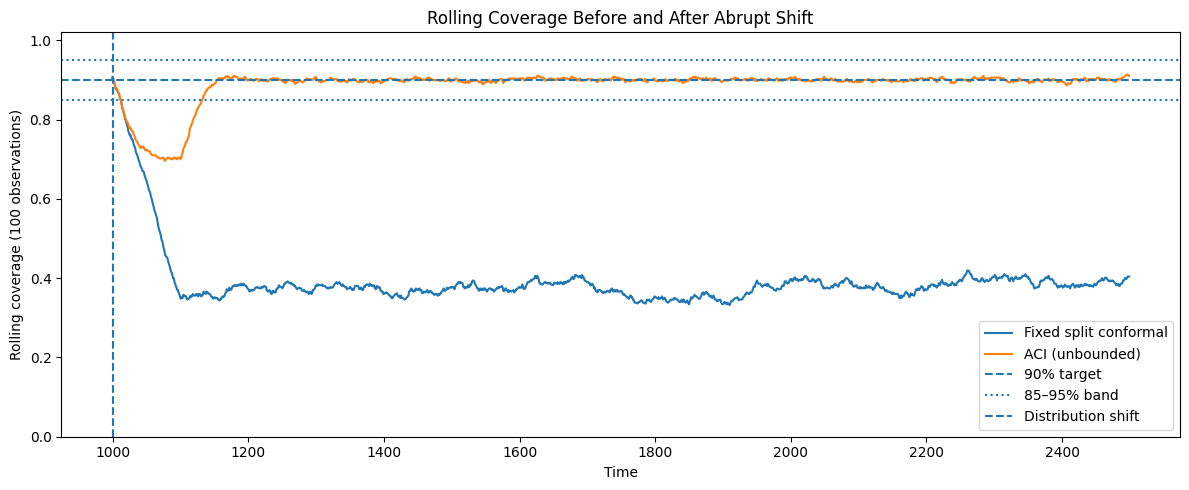

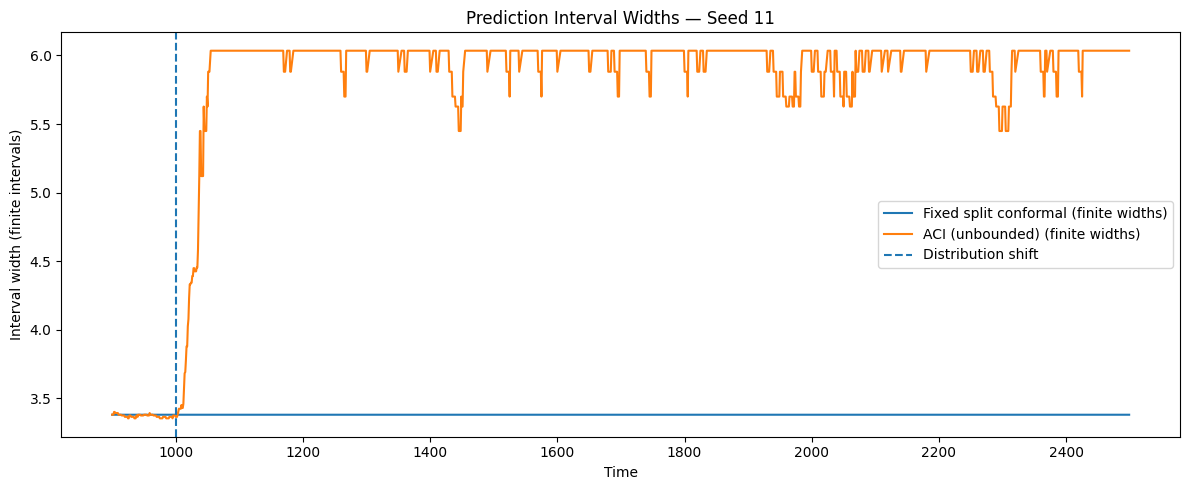

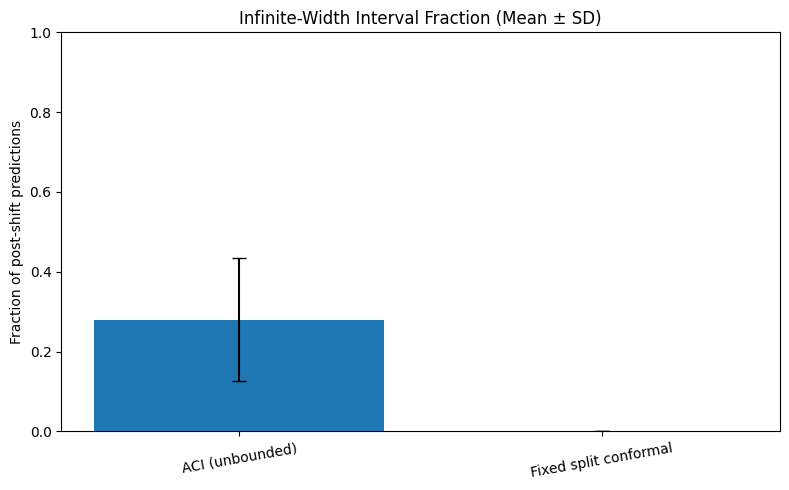

In [ ]:
# CELL 34 — Plot coverage, width, and infinite-width cost

methods = list(pilot_results["method"].unique())

# Figure 1: Mean rolling coverage across seeds
plt.figure(figsize=(12, 5))

for method in methods:
    subset = rolling_results[rolling_results["method"] == method]
    curve = subset.groupby("time")["rolling_coverage"].mean()
    plt.plot(curve.index, curve.values, label=method)

plt.axhline(TARGET_COVERAGE, linestyle="--", label="90% target")
plt.axhline(TARGET_COVERAGE - COVERAGE_TOLERANCE, linestyle=":", label="85–95% band")
plt.axhline(TARGET_COVERAGE + COVERAGE_TOLERANCE, linestyle=":")
plt.axvline(CHANGE_POINT, linestyle="--", label="Distribution shift")
plt.xlabel("Time")
plt.ylabel(f"Rolling coverage ({ROLLING_WINDOW} observations)")
plt.title("Rolling Coverage Before and After Abrupt Shift")
plt.ylim(0, 1.02)
plt.legend()
plt.tight_layout()
plt.show()


# Figure 2: Interval widths for one representative seed
example_seed = PILOT_SEEDS[0]
example = pilot_results[pilot_results["seed"] == example_seed]

plt.figure(figsize=(12, 5))

for method in methods:
    subset = example[example["method"] == method].sort_values("time")
    finite = np.isfinite(subset["width"])
    plt.plot(
        subset.loc[finite, "time"],
        subset.loc[finite, "width"],
        label=f"{method} (finite widths)"
    )

plt.axvline(CHANGE_POINT, linestyle="--", label="Distribution shift")
plt.xlabel("Time")
plt.ylabel("Interval width (finite intervals)")
plt.title(f"Prediction Interval Widths — Seed {example_seed}")
plt.legend()
plt.tight_layout()
plt.show()


# Figure 3: Infinite-width interval fraction by method and seed
infinite_summary = (
    seed_metrics.groupby("method")["infinite_width_fraction_post_shift"]
    .agg(["mean", "std"])
)

plt.figure(figsize=(8, 5))
plt.bar(
    infinite_summary.index,
    infinite_summary["mean"],
    yerr=infinite_summary["std"].fillna(0),
    capsize=5
)
plt.ylabel("Fraction of post-shift predictions")
plt.title("Infinite-Width Interval Fraction (Mean ± SD)")
plt.ylim(0, 1)
plt.xticks(rotation=10)
plt.tight_layout()
plt.show()

In [ ]:
# CELL 35 — Export experiment outputs

from pathlib import Path
import zipfile

OUTPUT_DIR = Path("/content/conformal_experiment_results")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

pilot_results.to_csv(
    OUTPUT_DIR / "raw_predictions.csv", index=False
)

seed_metrics.to_csv(
    OUTPUT_DIR / "per_seed_metrics.csv", index=False
)

summary.to_csv(
    OUTPUT_DIR / "pilot_summary.csv", index=False
)

rolling_results.to_csv(
    OUTPUT_DIR / "rolling_coverage.csv", index=False
)

# Record the experiment configuration for reproducibility.
config = pd.DataFrame([{
    "seeds": ",".join(map(str, PILOT_SEEDS)),
    "target_coverage": TARGET_COVERAGE,
    "alpha": ALPHA,
    "change_point": CHANGE_POINT,
    "n_observations": N_OBSERVATIONS,
    "train_end": TRAIN_END,
    "calibration_start": TRAIN_END,
    "calibration_end": CAL_END,
    "rolling_window": ROLLING_WINDOW,
    "coverage_tolerance": COVERAGE_TOLERANCE,
    "persistence": PERSISTENCE,
    "aci_gamma": GAMMA,
    "shift_size": 2.0,
    "methods": "Fixed split conformal; ACI (unbounded)",
    "status": "Five-seed synthetic pilot",
}])

config.to_csv(OUTPUT_DIR / "experiment_config.csv", index=False)

zip_path = "/content/conformal_experiment_results.zip"

with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as zf:
    for file_path in OUTPUT_DIR.iterdir():
        zf.write(file_path, arcname=file_path.name)

print("Export complete:")
for file_path in sorted(OUTPUT_DIR.iterdir()):
    print(f" - {file_path.name}")

print(f"\nZIP archive: {zip_path}")

from google.colab import files
files.download(zip_path)

Export complete:
 - experiment_config.csv
 - per_seed_metrics.csv
 - pilot_summary.csv
 - raw_predictions.csv
 - rolling_coverage.csv

ZIP archive: /content/conformal_experiment_results.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# Correctly distinguish recovery onset from confirmation

print(
    seed_metrics[
        [
            "seed",
            "method",
            "recovered",
            "recovery_time_from_shift",
            "confirmation_time_from_shift",
            "infinite_width_fraction_post_shift",
        ]
    ].to_string(index=False)
)

 seed                method  recovered  recovery_time_from_shift  confirmation_time_from_shift  infinite_width_fraction_post_shift
   11       ACI (unbounded)       True                     134.0                         183.0                            0.482000
   11 Fixed split conformal      False                       NaN                           NaN                            0.000000
   22       ACI (unbounded)       True                     141.0                         190.0                            0.310667
   22 Fixed split conformal      False                       NaN                           NaN                            0.000000
   33       ACI (unbounded)       True                     126.0                         175.0                            0.068667
   33 Fixed split conformal      False                       NaN                           NaN                            0.000000
   44       ACI (unbounded)       True                     127.0                   

In [ ]:

print("ACI update:")
print("alpha_(t+1) = alpha_t + gamma * (ALPHA - miss_t)")
print(f"Target alpha: {ALPHA}")
print(f"Gamma: {GAMMA}")
print(f"Calibration observations: {CAL_END - TRAIN_END}")
print(f"Initial calibration-score count: {len(cal_scores)}")
print(f"Predictor: {type(model).__name__}")
print("Boundary handling: alpha <= 0 gives an infinite interval; alpha >= 1 gives a point interval.")
print("Status: pilot implementation; paper-faithfulness not yet verified.")

ACI update:
alpha_(t+1) = alpha_t + gamma * (ALPHA - miss_t)
Target alpha: 0.09999999999999998
Gamma: 0.005
Calibration observations: 400
Initial calibration-score count: 400
Predictor: LinearRegression
Boundary handling: alpha <= 0 gives an infinite interval; alpha >= 1 gives a point interval.
Status: pilot implementation; paper-faithfulness not yet verified.


In [ ]:
# ACI implementation sanity check

alpha = 0.10
gamma = 0.005

# If the prediction MISSES:
alpha_after_miss = alpha + gamma * (alpha - 1)

# If the prediction COVERS:
alpha_after_cover = alpha + gamma * (alpha - 0)

print(f"After a miss:  {alpha_after_miss:.4f}")
print(f"After a cover: {alpha_after_cover:.4f}")

assert alpha_after_miss < alpha
assert alpha_after_cover > alpha

print("Update-direction checks passed.")

After a miss:  0.0955
After a cover: 0.1005
Update-direction checks passed.


In [ ]:
# Step 3 — Save the baseline configuration

baseline_config = {
    "target_coverage": target_coverage,
    "gamma_aci": GAMMA,
    "calibration_size": len(cal_scores),
    "change_point": change_point,
    "rolling_window": ROLLING_WINDOW,
    "coverage_tolerance": COVERAGE_TOLERANCE,
    "persistence": PERSISTENCE,
    "pilot_seeds": PILOT_SEEDS,
}

print("Baseline configuration saved in memory:")
for key, value in baseline_config.items():
    print(f"{key}: {value}")

Baseline configuration saved in memory:
target_coverage: 0.9
gamma_aci: 0.005
calibration_size: 400
change_point: 1000
rolling_window: 100
coverage_tolerance: 0.05
persistence: 50
pilot_seeds: [11, 22, 33, 44, 55]


In [ ]:
#  Record the official DtACI settings

DTACI_GAMMAS = np.array([
    0.001, 0.002, 0.004, 0.008,
    0.016, 0.032, 0.064, 0.128
])

DTACI_SIGMA = 1 / 1000
DTACI_ETA = 2.72

print("DtACI reference settings")
print("Candidate learning rates:", DTACI_GAMMAS)
print("Expert-weight smoothing:", DTACI_SIGMA)
print("Learning-rate parameter eta:", DTACI_ETA)
print("Reference implementation: DtACI.R")
print("Input required: sequential beta values derived from conformity scores")

DtACI reference settings
Candidate learning rates: [0.001 0.002 0.004 0.008 0.016 0.032 0.064 0.128]
Expert-weight smoothing: 0.001
Learning-rate parameter eta: 2.72
Reference implementation: DtACI.R
Input required: sequential beta values derived from conformity scores


DtACI test seed-1

In [ ]:

# CELL 36 — DtACI reference-aligned implementation

def run_dtaci_reference_port(seed=11, shift_size=2.0):
    rng = np.random.default_rng(seed + 100_000)

    X_dt, y_dt = generate_stream(seed=seed, shift_size=shift_size)

    model_dt = LinearRegression()
    model_dt.fit(X_dt[:TRAIN_END], y_dt[:TRAIN_END])

    cal_pred = model_dt.predict(X_dt[TRAIN_END:CAL_END])
    residual_history = list(
        np.abs(y_dt[TRAIN_END:CAL_END] - cal_pred)
    )

    gammas = np.asarray(DTACI_GAMMAS, dtype=float)
    k = len(gammas)

    expert_alpha = np.full(k, ALPHA, dtype=float)
    expert_weights = np.ones(k, dtype=float)
    expert_probs = np.full(k, 1.0 / k)

    current_expert = rng.integers(k)
    rows = []

    def reference_beta(previous_scores, current_score, epsilon=0.001):
        """Python port of the reference R findBeta() binary search."""
        scores = np.asarray(previous_scores, dtype=float)
        if len(scores) == 0:
            raise ValueError("Need previous residual scores.")

        top, bottom = 1.0, 0.0
        mid = 0.5

        while top - bottom > epsilon:
            q = np.quantile(scores, 1.0 - mid, method="linear")
            if q > current_score:
                bottom = mid
                mid = (top + bottom) / 2.0
            else:
                top = mid
                mid = (top + bottom) / 2.0

        return mid

    for t in range(CAL_END, len(y_dt)):
        prediction = float(model_dt.predict(X_dt[t:t + 1])[0])
        actual = float(y_dt[t])

        # Predict using only residuals available before time t.
        alpha_t = float(expert_alpha[current_expert])
        previous_scores = np.asarray(residual_history, dtype=float)

        lo, hi, width = make_interval(
            prediction, previous_scores, alpha_t
        )
        covered = int(lo <= actual <= hi)

        rows.append({
            "seed": seed,
            "time": t,
            "method": "DtACI",
            "y_true": actual,
            "lower": lo,
            "upper": hi,
            "covered": covered,
            "width": width,
            "alpha_t": alpha_t,
            "selected_gamma": float(gammas[current_expert]),
        })

        # Observe the outcome, then calculate beta from past residuals.
        residual = abs(actual - prediction)
        beta_t = reference_beta(previous_scores, residual)

        # Reference pinball loss, using expert alphas before their update.
        u = beta_t - expert_alpha
        losses = ALPHA * u - np.minimum(u, 0.0)

        # Update each expert.
        expert_alpha += gammas * (
            ALPHA - (expert_alpha > beta_t).astype(float)
        )

        # Reference exponential weights and fixed-share smoothing.
        weighted = expert_weights * np.exp(-DTACI_ETA * losses)
        total = weighted.sum()

        if not np.isfinite(total) or total <= 0:
            raise FloatingPointError("Invalid DtACI expert weights.")

        next_weights = (
            (1 - DTACI_SIGMA) * weighted / total
            + DTACI_SIGMA / k
        )
        expert_probs = next_weights / next_weights.sum()
        expert_weights = next_weights.copy()

        # Choose the expert for the next prediction.
        current_expert = rng.choice(k, p=expert_probs)

        # Current residual becomes available only after this prediction.
        residual_history.append(residual)

    return pd.DataFrame(rows)


# Validate one seed only — do not launch the full experiment yet.
dtaci_seed11 = run_dtaci_reference_port(seed=11)
post = dtaci_seed11[dtaci_seed11["time"] >= CHANGE_POINT]

print("DtACI validation — seed 11")
print("Rows:", len(dtaci_seed11))
print("Post-shift coverage:", round(post["covered"].mean(), 4))
print("Infinite-width fraction:", round(np.isinf(post["width"]).mean(), 4))
print("Mean selected alpha:", round(dtaci_seed11["alpha_t"].mean(), 4))
print("Selected learning rates:",
      sorted(dtaci_seed11["selected_gamma"].unique()))

display(dtaci_seed11.head())


DtACI validation — seed 11
Rows: 1600
Post-shift coverage: 0.902
Infinite-width fraction: 0.048
Mean selected alpha: 0.0584
Selected learning rates: [np.float64(0.001), np.float64(0.002), np.float64(0.004), np.float64(0.008), np.float64(0.016), np.float64(0.032), np.float64(0.064), np.float64(0.128)]


,seed,time,method,y_true,lower,upper,covered,width,alpha_t,selected_gamma
0,11,900,DtACI,-3.925224,-5.056848,-1.676063,1,3.380785,0.1000,0.004
1,11,901,DtACI,-0.782053,-2.217685,1.163099,1,3.380785,0.1016,0.016
2,11,902,DtACI,-3.530382,-3.414904,-0.034119,0,3.380785,0.1002,0.001
3,11,903,DtACI,-0.479464,-3.743451,-0.350137,1,3.393314,0.0993,0.001
4,11,904,DtACI,-1.069197,-2.363638,1.060842,1,3.424480,0.0952,0.008


In [ ]:

# DtACI five-seed pilot

pilot_seeds = [11, 22, 33, 44, 55]

dtaci_pilot = pd.concat(
    [
        run_dtaci_reference_port(seed=seed)
        for seed in pilot_seeds
    ],
    ignore_index=True
)

dtaci_pilot["phase"] = np.where(
    dtaci_pilot["time"] < CHANGE_POINT,
    "pre",
    "post"
)

post = dtaci_pilot[
    dtaci_pilot["time"] >= CHANGE_POINT
]

seed_summary = (
    post.groupby("seed")
    .agg(
        post_shift_coverage=("covered", "mean"),
        infinite_width_fraction=(
            "width",
            lambda x: np.isinf(x).mean()
        ),
        mean_width=("width", "mean")
    )
    .reset_index()
)

display(seed_summary.round(4))

print("\nOverall five-seed results")
print("Mean post-shift coverage:",
      round(post["covered"].mean(), 4))
print("Mean infinite-width fraction:",
      round(np.isinf(post["width"]).mean(), 4))


,seed,post_shift_coverage,infinite_width_fraction,mean_width
0,11,0.9020,0.0480,inf
1,22,0.9093,0.0333,inf
2,33,0.9013,0.0493,inf
3,44,0.9053,0.0373,inf
4,55,0.8993,0.0393,inf



Overall five-seed results
Mean post-shift coverage: 0.9035
Mean infinite-width fraction: 0.0415


In [ ]:

# DtACI width and recovery diagnostics

W = 100
LOWER_COVERAGE = 0.85
UPPER_COVERAGE = 0.95
PERSISTENCE = 50

diagnostics = []

for seed, group in dtaci_pilot.groupby("seed"):
    group = group.sort_values("time").reset_index(drop=True)
    post_mask = group["time"] >= CHANGE_POINT
    post = group.loc[post_mask].copy()

    # Finite widths only; report infinite-width rate separately.
    finite_widths = post.loc[
        np.isfinite(post["width"]), "width"
    ]

    # Rolling coverage, indexed by original time.
    group["rolling_coverage"] = (
        group["covered"].rolling(W, min_periods=W).mean()
    )

    eligible = group[
        (group["time"] >= CHANGE_POINT + W - 1)
        & group["rolling_coverage"].notna()
    ].copy()

    in_band = (
        (eligible["rolling_coverage"] >= LOWER_COVERAGE)
        & (eligible["rolling_coverage"] <= UPPER_COVERAGE)
    ).to_numpy()

    recovery_idx = None
    for i in range(len(in_band) - PERSISTENCE + 1):
        if in_band[i:i + PERSISTENCE].all():
            recovery_idx = int(eligible.iloc[i]["time"])
            break

    # Pre-shift width baseline: 100 observations before the shift.
    pre = group[
        (group["time"] >= CHANGE_POINT - 100)
        & (group["time"] < CHANGE_POINT)
    ]
    baseline_width = pre["width"].replace(
        [np.inf, -np.inf], np.nan
    ).mean()

    diagnostics.append({
        "seed": seed,
        "post_shift_coverage": post["covered"].mean(),
        "infinite_width_fraction": np.isinf(post["width"]).mean(),
        "mean_finite_width": (
            finite_widths.mean() if len(finite_widths) else np.nan
        ),
        "median_finite_width": (
            finite_widths.median() if len(finite_widths) else np.nan
        ),
        "pre_shift_baseline_width": baseline_width,
        "recovered": recovery_idx is not None,
        "recovery_time_from_shift": (
            recovery_idx - CHANGE_POINT
            if recovery_idx is not None else np.nan
        ),
    })

dtaci_diagnostics = pd.DataFrame(diagnostics)
display(dtaci_diagnostics.round(4))

print(
    "Recovered seeds:",
    int(dtaci_diagnostics["recovered"].sum()),
    "/",
    len(dtaci_diagnostics)
)


,seed,post_shift_coverage,infinite_width_fraction,mean_finite_width,median_finite_width,pre_shift_baseline_width,recovered,recovery_time_from_shift
0,11,0.9020,0.0480,6.7267,6.7660,3.4365,True,103
1,22,0.9093,0.0333,6.5468,6.5231,3.3224,True,99
2,33,0.9013,0.0493,6.8299,6.8295,3.3713,True,104
3,44,0.9053,0.0373,6.8099,6.9051,3.3355,True,99
4,55,0.8993,0.0393,6.8365,6.8022,3.4178,True,104


Recovered seeds: 5 / 5


In [ ]:

# CELL 39 — Unified pilot comparison with recovery metrics

all_pilot = pd.concat(
    [pilot_results, dtaci_pilot],
    ignore_index=True
)

all_pilot["phase"] = np.where(
    all_pilot["time"] < CHANGE_POINT, "pre", "post"
)

W = 100
LOWER_COVERAGE = 0.85
UPPER_COVERAGE = 0.95
PERSISTENCE = 50

comparison = []

for (method, seed), group in all_pilot.groupby(["method", "seed"]):
    group = group.sort_values("time").copy()
    post = group[group["time"] >= CHANGE_POINT]
    pre = group[
        (group["time"] >= CHANGE_POINT - 100)
        & (group["time"] < CHANGE_POINT)
    ]

    widths = post["width"].to_numpy(dtype=float)
    finite_widths = widths[np.isfinite(widths)]
    baseline_width = pre["width"].replace(
        [np.inf, -np.inf], np.nan
    ).mean()

    # Rolling coverage; only evaluate once the window is fully post-shift.
    group["rolling_coverage"] = (
        group["covered"].rolling(W, min_periods=W).mean()
    )

    eligible = group[
        (group["time"] >= CHANGE_POINT + W - 1)
        & group["rolling_coverage"].notna()
    ].copy()

    in_band = (
        (eligible["rolling_coverage"] >= LOWER_COVERAGE)
        & (eligible["rolling_coverage"] <= UPPER_COVERAGE)
    ).to_numpy()

    recovery_onset = None
    confirmation_time = None

    for i in range(len(in_band) - PERSISTENCE + 1):
        if in_band[i:i + PERSISTENCE].all():
            recovery_onset = int(eligible.iloc[i]["time"])
            confirmation_time = int(
                eligible.iloc[i + PERSISTENCE - 1]["time"]
            )
            break

    comparison.append({
        "method": method,
        "seed": seed,
        "post_shift_coverage": post["covered"].mean(),
        "infinite_width_fraction": np.isinf(widths).mean(),
        "mean_finite_width": (
            finite_widths.mean() if len(finite_widths) else np.nan
        ),
        "pre_shift_baseline_width": baseline_width,
        "finite_width_inflation_ratio": (
            finite_widths.mean() / baseline_width
            if len(finite_widths) and pd.notna(baseline_width)
            and baseline_width > 0 else np.nan
        ),
        "recovered": recovery_onset is not None,
        "recovery_onset_from_shift": (
            recovery_onset - CHANGE_POINT
            if recovery_onset is not None else np.nan
        ),
        "confirmation_time_from_shift": (
            confirmation_time - CHANGE_POINT
            if confirmation_time is not None else np.nan
        ),
    })

comparison_df = pd.DataFrame(comparison)

summary_df = (
    comparison_df.groupby("method")
    .agg(
        seeds=("seed", "nunique"),
        mean_coverage=("post_shift_coverage", "mean"),
        sd_coverage=("post_shift_coverage", "std"),
        mean_infinite_fraction=("infinite_width_fraction", "mean"),
        mean_finite_width=("mean_finite_width", "mean"),
        mean_pre_shift_width=("pre_shift_baseline_width", "mean"),
        mean_finite_width_inflation=(
            "finite_width_inflation_ratio", "mean"
        ),
        recovery_rate=("recovered", "mean"),
        mean_recovery_onset=("recovery_onset_from_shift", "mean"),
        mean_confirmation_time=("confirmation_time_from_shift", "mean"),
    )
    .reset_index()
)

display(summary_df.round(4))
display(comparison_df.round(4))


,method,seeds,mean_coverage,sd_coverage,mean_infinite_fraction,mean_finite_width,mean_pre_shift_width,mean_finite_width_inflation,recovery_rate,mean_recovery_onset,mean_confirmation_time
0,ACI (unbounded),5,0.8877,0.0014,0.2805,6.1846,3.3389,1.8528,1.0,132.2,181.2
1,DtACI,5,0.9035,0.0039,0.0415,6.7500,3.3767,1.9992,1.0,101.8,150.8
2,Fixed split conformal,5,0.3753,0.0197,0.0000,3.3436,3.3436,1.0000,0.0,NaN,NaN


,method,seed,post_shift_coverage,infinite_width_fraction,mean_finite_width,pre_shift_baseline_width,finite_width_inflation_ratio,recovered,recovery_onset_from_shift,confirmation_time_from_shift
0,ACI (unbounded),11,0.8867,0.4820,5.8304,3.3721,1.7290,True,134.0,183.0
1,ACI (unbounded),22,0.8880,0.3107,5.9094,3.3266,1.7764,True,141.0,190.0
2,ACI (unbounded),33,0.8860,0.0687,6.7501,3.3593,2.0094,True,126.0,175.0
3,ACI (unbounded),44,0.8893,0.3320,6.1809,3.2281,1.9147,True,127.0,176.0
4,ACI (unbounded),55,0.8887,0.2093,6.2522,3.4084,1.8344,True,133.0,182.0
5,DtACI,11,0.9020,0.0480,6.7267,3.4365,1.9575,True,103.0,152.0
6,DtACI,22,0.9093,0.0333,6.5468,3.3224,1.9705,True,99.0,148.0
7,DtACI,33,0.9013,0.0493,6.8299,3.3713,2.0259,True,104.0,153.0
8,DtACI,44,0.9053,0.0373,6.8099,3.3355,2.0416,True,99.0,148.0
9,DtACI,55,0.8993,0.0393,6.8365,3.4178,2.0002,True,104.0,153.0


In [ ]:

# CELL 40 — Main experiment: 30 seeds per method

MAIN_SEEDS = list(range(100, 130))

main_results = []

for i, seed in enumerate(MAIN_SEEDS, start=1):
    print(f"Seed {i}/{len(MAIN_SEEDS)}: {seed}")

    # Fixed split conformal and ACI
    result = run_one_seed(seed=seed, shift_size=2.0)
    main_results.append(result)

    # DtACI
    dtaci_result = run_dtaci_reference_port(
        seed=seed, shift_size=2.0
    )
    main_results.append(dtaci_result)

main_predictions = pd.concat(main_results, ignore_index=True)

main_predictions["phase"] = np.where(
    main_predictions["time"] < CHANGE_POINT, "pre", "post"
)

main_predictions.to_csv(
    "main_experiment_raw_predictions.csv", index=False
)

print("\nMain experiment complete.")
print("Rows:", len(main_predictions))
print("Seeds per method:", MAIN_SEEDS[0], "to", MAIN_SEEDS[-1])
print("Methods:", main_predictions["method"].unique())

display(main_predictions.head())


Seed 1/30: 100
Seed 2/30: 101
Seed 3/30: 102
Seed 4/30: 103
Seed 5/30: 104
Seed 6/30: 105
Seed 7/30: 106
Seed 8/30: 107
Seed 9/30: 108
Seed 10/30: 109
Seed 11/30: 110
Seed 12/30: 111
Seed 13/30: 112
Seed 14/30: 113
Seed 15/30: 114
Seed 16/30: 115
Seed 17/30: 116
Seed 18/30: 117
Seed 19/30: 118
Seed 20/30: 119
Seed 21/30: 120
Seed 22/30: 121
Seed 23/30: 122
Seed 24/30: 123
Seed 25/30: 124
Seed 26/30: 125
Seed 27/30: 126
Seed 28/30: 127
Seed 29/30: 128
Seed 30/30: 129

Main experiment complete.
Rows: 144000
Seeds per method: 100 to 129
Methods: ['Fixed split conformal' 'ACI (unbounded)' 'DtACI']


,seed,time,method,y_true,lower,upper,covered,width,alpha_t,selected_gamma,phase
0,100,900,Fixed split conformal,-0.078401,-3.305747,-0.029654,1,3.276093,0.1000,NaN,pre
1,100,900,ACI (unbounded),-0.078401,-3.305747,-0.029654,1,3.276093,0.1000,NaN,pre
2,100,901,Fixed split conformal,2.193210,0.615504,3.891597,1,3.276093,0.1000,NaN,pre
3,100,901,ACI (unbounded),2.193210,0.615504,3.891597,1,3.276093,0.1005,NaN,pre
4,100,902,Fixed split conformal,1.551519,-1.304900,1.971193,1,3.276093,0.1000,NaN,pre


In [ ]:

# Validate main experiment output

print("Rows:", len(main_predictions))
print("\nMethods and number of seeds:")
display(
    main_predictions.groupby("method")["seed"]
    .nunique()
    .rename("unique_seeds")
    .to_frame()
)

print("\nRows per method:")
display(main_predictions.groupby("method").size().to_frame("rows"))

print("\nMissing values in essential columns:")
display(
    main_predictions[
        ["seed", "time", "method", "covered", "width"]
    ].isna().sum().to_frame("missing_values")
)

print("\nSeed range:", main_predictions["seed"].min(),
      "to", main_predictions["seed"].max())
print("Saved CSV exists if this completed without error:",
      "main_experiment_raw_predictions.csv")


Rows: 144000

Methods and number of seeds:


,unique_seeds
method,
ACI (unbounded),30
DtACI,30
Fixed split conformal,30



Rows per method:


,rows
method,
ACI (unbounded),48000
DtACI,48000
Fixed split conformal,48000



Missing values in essential columns:


,missing_values
seed,0
time,0
method,0
covered,0
width,0



Seed range: 100 to 129
Saved CSV exists if this completed without error: main_experiment_raw_predictions.csv


This is our first genuinely useful comparison. The pilot suggests that ACI and DtACI achieve much better post-shift coverage than fixed split conformal, but they pay for adaptation with wider prediction intervals. DtACI looks particularly promising on the reliability–efficiency trade-off.

In [ ]:

# CELL 42 — Main experiment: recovery and efficiency metrics

W = 100
LOWER_COVERAGE = 0.85
UPPER_COVERAGE = 0.95
PERSISTENCE = 50

main_metrics = []

for (method, seed), group in main_predictions.groupby(["method", "seed"]):
    group = group.sort_values("time").copy()

    post = group[group["time"] >= CHANGE_POINT]
    pre = group[
        (group["time"] >= CHANGE_POINT - 100)
        & (group["time"] < CHANGE_POINT)
    ]

    widths = post["width"].to_numpy(dtype=float)
    finite_widths = widths[np.isfinite(widths)]
    baseline_width = pre["width"].replace(
        [np.inf, -np.inf], np.nan
    ).mean()

    group["rolling_coverage"] = (
        group["covered"].rolling(W, min_periods=W).mean()
    )

    eligible = group[
        (group["time"] >= CHANGE_POINT + W - 1)
        & group["rolling_coverage"].notna()
    ]

    in_band = (
        (eligible["rolling_coverage"] >= LOWER_COVERAGE)
        & (eligible["rolling_coverage"] <= UPPER_COVERAGE)
    ).to_numpy()

    onset = None
    confirmation = None

    for i in range(len(in_band) - PERSISTENCE + 1):
        if in_band[i:i + PERSISTENCE].all():
            onset = int(eligible.iloc[i]["time"])
            confirmation = int(
                eligible.iloc[i + PERSISTENCE - 1]["time"]
            )
            break

    main_metrics.append({
        "method": method,
        "seed": seed,
        "post_shift_coverage": post["covered"].mean(),
        "infinite_width_fraction": np.isinf(widths).mean(),
        "mean_finite_width": (
            finite_widths.mean() if len(finite_widths) else np.nan
        ),
        "pre_shift_baseline_width": baseline_width,
        "finite_width_inflation_ratio": (
            finite_widths.mean() / baseline_width
            if len(finite_widths) and pd.notna(baseline_width)
            and baseline_width > 0 else np.nan
        ),
        "recovered": onset is not None,
        "recovery_onset_from_shift": (
            onset - CHANGE_POINT if onset is not None else np.nan
        ),
        "confirmation_time_from_shift": (
            confirmation - CHANGE_POINT
            if confirmation is not None else np.nan
        ),
    })

main_metrics_df = pd.DataFrame(main_metrics)

main_summary = (
    main_metrics_df.groupby("method")
    .agg(
        seeds=("seed", "nunique"),
        mean_coverage=("post_shift_coverage", "mean"),
        sd_coverage=("post_shift_coverage", "std"),
        mean_infinite_fraction=("infinite_width_fraction", "mean"),
        mean_finite_width=("mean_finite_width", "mean"),
        mean_baseline_width=("pre_shift_baseline_width", "mean"),
        mean_width_inflation=("finite_width_inflation_ratio", "mean"),
        recovery_rate=("recovered", "mean"),
        mean_recovery_onset=("recovery_onset_from_shift", "mean"),
        mean_confirmation_time=("confirmation_time_from_shift", "mean"),
    )
    .reset_index()
)

display(main_summary.round(4))

main_metrics_df.to_csv("main_experiment_per_seed_metrics.csv", index=False)
main_summary.to_csv("main_experiment_summary.csv", index=False)

print("Saved main_experiment_per_seed_metrics.csv")
print("Saved main_experiment_summary.csv")


,method,seeds,mean_coverage,sd_coverage,mean_infinite_fraction,mean_finite_width,mean_baseline_width,mean_width_inflation,recovery_rate,mean_recovery_onset,mean_confirmation_time
0,ACI (unbounded),30,0.8873,0.0018,0.3396,6.0137,3.3419,1.8034,1.0,134.0333,183.0333
1,DtACI,30,0.9031,0.0042,0.0404,6.6991,3.3721,1.9911,1.0,104.9000,153.9000
2,Fixed split conformal,30,0.3676,0.0350,0.0000,3.3350,3.3350,1.0000,0.0,NaN,NaN


Saved main_experiment_per_seed_metrics.csv
Saved main_experiment_summary.csv


# sensitivity test


In [ ]:


SHIFT_SIZES = [1.0, 2.0, 3.0]
SENSITIVITY_SEEDS = list(range(100, 130))
sensitivity_runs = []

for shift in SHIFT_SIZES:
    for i, seed in enumerate(SENSITIVITY_SEEDS, start=1):
        print(f"Shift {shift} | seed {i}/30")

        fixed_aci = run_one_seed(seed=seed, shift_size=shift)
        fixed_aci["shift_size"] = shift
        sensitivity_runs.append(fixed_aci)

        dtaci = run_dtaci_reference_port(seed=seed, shift_size=shift)
        dtaci["shift_size"] = shift
        sensitivity_runs.append(dtaci)

sensitivity_predictions = pd.concat(
    sensitivity_runs, ignore_index=True
)

# Calculate per-seed metrics
sensitivity_metrics = []

for (shift, method, seed), group in sensitivity_predictions.groupby(
    ["shift_size", "method", "seed"]
):
    group = group.sort_values("time").copy()
    post = group[group["time"] >= CHANGE_POINT]
    widths = post["width"].to_numpy(dtype=float)
    finite_widths = widths[np.isfinite(widths)]

    group["rolling_coverage"] = (
        group["covered"].rolling(100, min_periods=100).mean()
    )
    eligible = group[
        (group["time"] >= CHANGE_POINT + 99)
        & group["rolling_coverage"].notna()
    ]
    in_band = (
        (eligible["rolling_coverage"] >= 0.85)
        & (eligible["rolling_coverage"] <= 0.95)
    ).to_numpy()

    onset = confirmation = None
    for j in range(len(in_band) - 49):
        if in_band[j:j + 50].all():
            onset = int(eligible.iloc[j]["time"]) - CHANGE_POINT
            confirmation = (
                int(eligible.iloc[j + 49]["time"]) - CHANGE_POINT
            )
            break

    sensitivity_metrics.append({
        "shift_size": shift,
        "method": method,
        "seed": seed,
        "coverage": post["covered"].mean(),
        "infinite_fraction": np.isinf(widths).mean(),
        "mean_finite_width": (
            finite_widths.mean() if len(finite_widths) else np.nan
        ),
        "recovered": onset is not None,
        "recovery_onset": onset,
        "confirmation_time": confirmation,
    })

sensitivity_metrics_df = pd.DataFrame(sensitivity_metrics)

sensitivity_summary = (
    sensitivity_metrics_df.groupby(["shift_size", "method"])
    .agg(
        seeds=("seed", "nunique"),
        mean_coverage=("coverage", "mean"),
        sd_coverage=("coverage", "std"),
        infinite_fraction=("infinite_fraction", "mean"),
        mean_finite_width=("mean_finite_width", "mean"),
        recovery_rate=("recovered", "mean"),
        mean_recovery_onset=("recovery_onset", "mean"),
        mean_confirmation_time=("confirmation_time", "mean"),
    )
    .reset_index()
)

display(sensitivity_summary.round(4))

sensitivity_metrics_df.to_csv(
    "sensitivity_per_seed_metrics.csv", index=False
)
sensitivity_summary.to_csv(
    "sensitivity_summary.csv", index=False
)


Shift 1.0 | seed 1/30
Shift 1.0 | seed 2/30
Shift 1.0 | seed 3/30
Shift 1.0 | seed 4/30
Shift 1.0 | seed 5/30
Shift 1.0 | seed 6/30
Shift 1.0 | seed 7/30
Shift 1.0 | seed 8/30
Shift 1.0 | seed 9/30
Shift 1.0 | seed 10/30
Shift 1.0 | seed 11/30
Shift 1.0 | seed 12/30
Shift 1.0 | seed 13/30
Shift 1.0 | seed 14/30
Shift 1.0 | seed 15/30
Shift 1.0 | seed 16/30
Shift 1.0 | seed 17/30
Shift 1.0 | seed 18/30
Shift 1.0 | seed 19/30
Shift 1.0 | seed 20/30
Shift 1.0 | seed 21/30
Shift 1.0 | seed 22/30
Shift 1.0 | seed 23/30
Shift 1.0 | seed 24/30
Shift 1.0 | seed 25/30
Shift 1.0 | seed 26/30
Shift 1.0 | seed 27/30
Shift 1.0 | seed 28/30
Shift 1.0 | seed 29/30
Shift 1.0 | seed 30/30
Shift 2.0 | seed 1/30
Shift 2.0 | seed 2/30
Shift 2.0 | seed 3/30
Shift 2.0 | seed 4/30
Shift 2.0 | seed 5/30
Shift 2.0 | seed 6/30
Shift 2.0 | seed 7/30
Shift 2.0 | seed 8/30
Shift 2.0 | seed 9/30
Shift 2.0 | seed 10/30
Shift 2.0 | seed 11/30
Shift 2.0 | seed 12/30
Shift 2.0 | seed 13/30
Shift 2.0 | seed 14/30
Shift 

,shift_size,method,seeds,mean_coverage,sd_coverage,infinite_fraction,mean_finite_width,recovery_rate,mean_recovery_onset,mean_confirmation_time
0,1.0,ACI (unbounded),30,0.8900,0.0021,0.0032,4.5483,1.0000,185.7000,234.7000
1,1.0,DtACI,30,0.8987,0.0034,0.0154,4.6432,1.0000,123.9000,172.9000
2,1.0,Fixed split conformal,30,0.7385,0.0338,0.0000,3.3350,0.0667,896.0000,945.0000
3,2.0,ACI (unbounded),30,0.8873,0.0018,0.3396,6.0137,1.0000,134.0333,183.0333
4,2.0,DtACI,30,0.9031,0.0042,0.0404,6.6991,1.0000,104.9000,153.9000
5,2.0,Fixed split conformal,30,0.3676,0.0350,0.0000,3.3350,0.0000,NaN,NaN
6,3.0,ACI (unbounded),30,0.8869,0.0017,0.7156,6.3614,1.0000,118.3333,167.3333
7,3.0,DtACI,30,0.9043,0.0038,0.0503,8.7132,1.0000,104.5000,153.5000
8,3.0,Fixed split conformal,30,0.0930,0.0170,0.0000,3.3350,0.0000,NaN,NaN
